# Практическое занятие №1. Линейная регрессия

**Студент:** Галимский Дмитрий, группа 413м

---

## Постановка задачи

Датасет **California Housing** из `sklearn.datasets`: 20640 административных
районов (census block group) штата Калифорния по данным переписи населения США
1990 года. Для каждого района измерены средний доход домохозяйства, возраст
домов, среднее число комнат и спален, население, заселённость жилья и
координаты. Последний столбец `MedHouseVal` - **средняя стоимость дома в
сотнях тысяч долларов**.

Задача - **предсказать среднюю цену дома в районе по восьми числовым
признакам**.

Что делаем и зачем:

1. **Данные** - загружаем датасет одной командой `fetch_california_housing()`,
   разбираемся, что в нём есть и в каких единицах.
2. **Проверка и очистка** - дубликаты, пропуски, аномалии. Даже если датасет
   чистый, код проверки обязателен: он показывает, что мы действительно
   смотрели на данные, а не просто начитали с ними работу.
3. **Разведочный анализ** - распределения, география цен, матрица корреляций.
4. **Подготовка** - масштабирование числовых признаков, разделение на
   train / validation / test.
5. **Модель** - линейная регрессия (метод наименьших квадратов).
6. **Обучение и оценка** - выбор кандидата по валидации, метрики на тесте,
   сравнение с базовой линией и разбор ошибок.

## Почему линейная регрессия

Средняя цена дома - физическая величина, которая растёт с доходом населения и
падает с удалённостью от центра, поэтому ожидается почти линейная связь:
«беднее район - дешевле дом». Линейная регрессия - самая простая и самая
интерпретируемая модель: у каждого признака есть коэффициент, который можно
прочитать и осмыслить. Это честная отправная точка, с которой потом сравнивают
всё остальное.

Работа построена так, чтобы результат был **честным**: выбор модели делается по
валидационной выборке, тестовая используется один раз в самом конце.


In [1]:
# Зависимости.

%pip install -q numpy pandas scikit-learn matplotlib seaborn

# Проверка
import importlib

for _package in ("numpy", "pandas", "sklearn", "matplotlib", "seaborn"):
    _module = importlib.import_module(_package)
    print(f"{_package:12s} {_module.__version__}")


Note: you may need to restart the kernel to use updated packages.
numpy        2.5.3


pandas       3.0.5


sklearn      1.9.1


matplotlib   3.11.2


seaborn      0.13.2


In [2]:
# Все импорты

from statistics import NormalDist           # теоретические квантили нормального распределения для Q-Q графика

import numpy as np                         # численные массивы
import pandas as pd                        # таблицы: чтение данных, статистика, группировки
import matplotlib.pyplot as plt             # базовые графики
import seaborn as sns                       # читаемые графики и тепловая карта корреляций

from sklearn.datasets import fetch_california_housing   # официальный загрузчик датасета California Housing
from sklearn.model_selection import train_test_split    # разделение на train / validation / test
from sklearn.preprocessing import StandardScaler         # масштабирование числовых признаков
from sklearn.preprocessing import PolynomialFeatures    # нелинейные признаки для контрольного эксперимента
from sklearn.pipeline import Pipeline                    # «преобразования → модель», чтобы не допустить утечки
from sklearn.linear_model import LinearRegression, Ridge  # сама модель и её регуляризованный вариант
from sklearn.dummy import DummyRegressor                 # базовая линия: предсказание среднего
from sklearn.metrics import (                            # метрики качества регрессии
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score,
)


In [3]:

SEED = 42
np.random.seed(SEED)

# Графики должны попадать в вывод ноутбука как картинки - это делает inline-режим.
%matplotlib inline

# Единый стиль оформления всех графиков.
sns.set_theme(style="whitegrid")            # включает сетку на белом фоне
plt.rcParams["figure.figsize"] = (10, 5)    # размер рисунка
plt.rcParams["font.size"] = 11              # размер шрифтов для подписей
pd.set_option("display.max_columns", None)  # видны все таблицы
pd.set_option("display.max_colwidth", 70)   # сколько символов в одном ячейке
pd.set_option("display.width", 140)         # какая ширина экрана


## 1. Данные

**California Housing** - классический набор для регрессии, который входит в
`sklearn.datasets`. Файл с данными уже лежит в пакете `scikit-learn`, поэтому
датасет воспроизводится одной командой без ручного скачивания: ноутбук
одинаково запускается на любой машине и в облаке.

Схема данных: 20640 строк, 8 числовых признаков, все они **числовые** -
кодировать категории и заполнять пропуски нечего, но проверять это мы всё
равно обязаны. Целевая переменная `MedHouseVal` лежит последним столбцом и
измеряется в сотнях тысяч долларов: 1.0 означает 100 000 долларов.

Важная особенность: каждая строка - это не отдельный дом, а **средние по
району**. Почти все признаки, кроме координат, - усреднённые величины, а сам
район описан в исходном наборе как census block group, то есть группа домов
численностью примерно от 600 до 3000 человек.


In [4]:
# датасет
housing = fetch_california_housing()

# список призноков и целевого признака
FEATURE_COLUMNS = list(housing.feature_names)
TARGET = "MedHouseVal"

# создание полноценной таблицы и столбика с ЦелПри
data = pd.DataFrame(housing.data, columns=FEATURE_COLUMNS)
data[TARGET] = housing.target

print(f"объект: {type(housing).__name__}, признаков: {len(FEATURE_COLUMNS)}, строк: {len(data)}")
print(f"имена признаков: {FEATURE_COLUMNS}")

# Печатаем абзац из документации набора: он объясняет, что именно означает
# строка таблицы. Это проверяемый первоисточник, а не наше предположение.
#description_lines = housing.DESCR.splitlines()
#start = next(i for i, line in enumerate(description_lines) if "one row per census" in line)
#print()


#print("\n".join(line for line in description_lines[start:start + 4] if line.strip()))
data.head()


объект: Bunch, признаков: 8, строк: 20640
имена признаков: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [5]:
# Красивое описание датасета

MEANING = pd.DataFrame({
    "признак": FEATURE_COLUMNS + [TARGET],
    "единица": [
        "десятки тысяч $ в год",
        "годы",
        "комнат на домохозяйство",
        "спален на домохозяйство",
        "человек",
        "жильцов на домохозяйство",
        "градусы",
        "градусы",
        "сотни тысяч $",
    ],
    "смысл": [
        "средний доход домохозяйства района",
        "возраст дома на момент переписи",
        "среднее число комнат в доме",
        "среднее число спален в доме",
        "население района",
        "население, делённое на число домохозяйств",
        "широта: положение на севере",
        "долгота: положение на востоке",
        "средняя стоимость дома (целевая переменная)",
    ],
}).set_index("признак")

# чтобы были столбцы минимумы и максимумы
MEANING["минимум"] = data[MEANING.index].min().round(3)
MEANING["максимум"] = data[MEANING.index].max().round(3)
MEANING


,единица,смысл,минимум,максимум
признак,,,,
MedInc,десятки тысяч $ в год,средний доход домохозяйства района,0.500,15.000
HouseAge,годы,возраст дома на момент переписи,1.000,52.000
AveRooms,комнат на домохозяйство,среднее число комнат в доме,0.846,141.909
AveBedrms,спален на домохозяйство,среднее число спален в доме,0.333,34.067
Population,человек,население района,3.000,35682.000
AveOccup,жильцов на домохозяйство,"население, делённое на число домохозяйств",0.692,1243.333
Latitude,градусы,широта: положение на севере,32.540,41.950
Longitude,градусы,долгота: положение на востоке,-124.350,-114.310
MedHouseVal,сотни тысяч $,средняя стоимость дома (целевая переменная),0.150,5.000


In [6]:
# вывод типов данных,

print(data.dtypes)
print()
print(data.describe().round(3).T)

# count	сколько непустых значений	
# mean	среднее	нет
# std	стандартное отклонение, разброс	
# min	минимум	нет
# 25%	первая квартиль, ниже неё четверть данных	
# 50%	медиана, ровно посередине	
# 75%	третья квартиль	
# max	максимум	


MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

               count      mean       std      min      25%       50%       75%        max
MedInc       20640.0     3.871     1.900    0.500    2.563     3.535     4.743     15.000
HouseAge     20640.0    28.639    12.586    1.000   18.000    29.000    37.000     52.000
AveRooms     20640.0     5.429     2.474    0.846    4.441     5.229     6.052    141.909
AveBedrms    20640.0     1.097     0.474    0.333    1.006     1.049     1.100     34.067
Population   20640.0  1425.477  1132.462    3.000  787.000  1166.000  1725.000  35682.000
AveOccup     20640.0     3.071    10.386    0.692    2.430     2.818     3.282   1243.333
Latitude     20640.0    35.632     2.136   32.540   33.930    34.260    37.710     41.950
Longitude    20640.0  -119.570     2.004 -124.350 -121.800

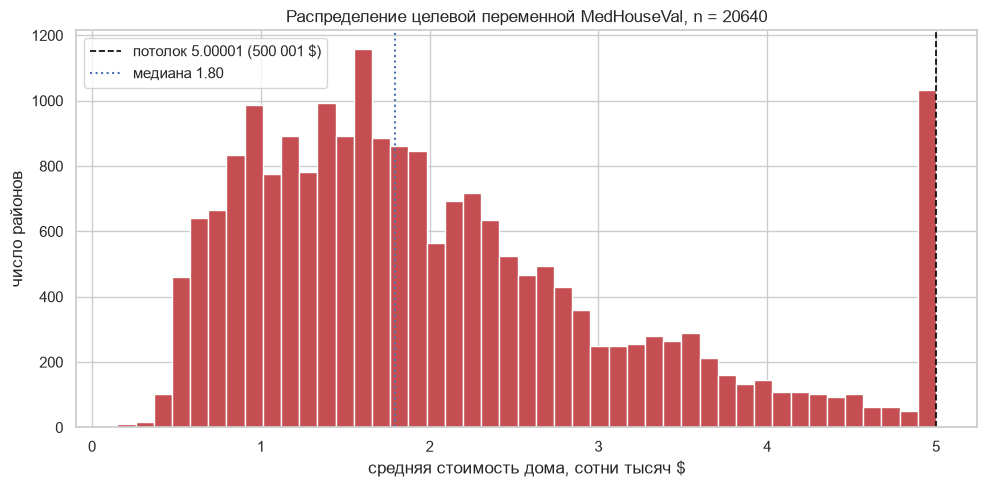

In [7]:
# график целевой переменной
figure, axis = plt.subplots(figsize=(10, 5))
axis.hist(data[TARGET], bins=45, color="#c44e52", edgecolor="white")
axis.axvline(5.00001, color="black", linestyle="--", linewidth=1.2,
             label="потолок 5.00001 (500 001 $)")
axis.axvline(data[TARGET].median(), color="#4c72b0", linestyle=":",
             label=f"медиана {data[TARGET].median():.2f}")
axis.set_xlabel("средняя стоимость дома, сотни тысяч $")
axis.set_ylabel("число районов")
axis.set_title("Распределение целевой переменной MedHouseVal, n = %d" % len(data))
axis.legend()
figure.tight_layout()
plt.show()


## 2. Проверка и очистка

Проверяем датасет по четырём фронтам:

1. **пропуски** (`NaN`, пустые поля);
2. **дубликаты** - и полные повторы строк, и повторы по набору признаков;
3. **физически невозможные значения** - например, 132 комнаты на домохозяйство;
4. **статистические выбросы** - правило «забора Тьюки». (поиск значений, которые слишком далеко от остальных.)

Плюс одна проверка, которая есть далеко не в каждом наборе: в этом датасете
признаки связаны формулой (`число домохозяйств = Population / AveOccup`), и мы
проверим, что она сходится.




In [8]:
# Пропуски 

missing = data.isna().sum()
missing_frame = pd.DataFrame({"пропусков": missing, "доля": (missing / len(data)).round(4)})
print(f"всего пропусков в таблице: {int(missing.sum())}")
print(f"строк хотя бы с одним пропуском: {int(data.isna().any(axis=1).sum())}")
missing_frame


всего пропусков в таблице: 0
строк хотя бы с одним пропуском: 0


,пропусков,доля
MedInc,0,0.0
HouseAge,0,0.0
AveRooms,0,0.0
AveBedrms,0,0.0
Population,0,0.0
AveOccup,0,0.0
Latitude,0,0.0
Longitude,0,0.0
MedHouseVal,0,0.0


In [9]:
# Если пропуски есть, заполняются медианной
numeric_columns = data.select_dtypes("number").columns.tolist()
medians = data[numeric_columns].median()

clean = data.copy()
clean[numeric_columns] = clean[numeric_columns].fillna(medians)
print("пропусков до заполнения:", int(data.isna().sum().sum()),
      "· после:", int(clean.isna().sum().sum()))
print("медианы числовых признаков:")
medians.round(3)


пропусков до заполнения: 0 · после: 0
медианы числовых признаков:


MedInc            3.535
HouseAge         29.000
AveRooms          5.229
AveBedrms         1.049
Population     1166.000
AveOccup          2.818
Latitude         34.260
Longitude      -118.490
MedHouseVal       1.797
dtype: float64

In [10]:
# Дубликаты

full_duplicates = int(clean.duplicated().sum())
feature_duplicates = int(clean.duplicated(subset=FEATURE_COLUMNS).sum())

print(f"полных дубликатов строк: {full_duplicates}")
print(f"повторов по набору признаков (без цели): {feature_duplicates}")
print(f"строк после удаления полных дубликатов: {len(clean) - full_duplicates}")

# Отдельно смотрим, не подменяет ли кто-то «разные районы» одной точкой на карте.
coordinate_pairs = clean[["Latitude", "Longitude"]].drop_duplicates()
print(f"уникальных пар координат: {len(coordinate_pairs)} при {len(clean)} строках")
print("повторы по координатам удалять нельзя: это разные районы в одной точке")


полных дубликатов строк: 0
повторов по набору признаков (без цели): 0
строк после удаления полных дубликатов: 20640
уникальных пар координат: 12590 при 20640 строках
повторы по координатам удалять нельзя: это разные районы в одной точке


In [11]:
# Проверка согласованности: признаки этого
# датасета связаны формулой. Число домохозяйств в районе равно
# Population / AveOccup, и оно обязано быть целым числом. Если бы где-то не
# сошлось, это означало бы ошибку округления при сборке данных.


households = clean["Population"] / clean["AveOccup"]
fractional_part = (households - households.round()).abs()

print(f"строк с нецелым числом домохозяйств: {int((fractional_part > 0.01).sum())} из {len(clean)}")
print(f"домохозяйств на район: от {households.min():.0f} до {households.max():.0f}, "
      f"медиана {households.median():.0f}")

# В исходном описании набора жилищных данных есть эвристика: на домохозяйство
# не может приходиться 5-7 жильцов (либо меньше 5, либо больше 7). Проверяем её
# как пример «домысленной» проверки, которую не видно ни в одной гистограмме.
forbidden_band = (clean["AveOccup"] >= 5) & (clean["AveOccup"] < 7)
print(f"строк с 5-7 жильцами на домохозяйство: {int(forbidden_band.sum())} "
      f"({forbidden_band.mean():.2%})")


строк с нецелым числом домохозяйств: 0 из 20640
домохозяйств на район: от 1 до 6082, медиана 409
строк с 5-7 жильцами на домохозяйство: 276 (1.34%)


In [12]:
# Аномалии 1

LIMITS = {
    "MedInc": (0.0, 20.0),        # десятки тысяч долларов в год
    "HouseAge": (0.0, 100.0),     # лет дому не может быть больше века
    "AveRooms": (0.0, 20.0),      # больше 20 комнат на домохозяйство - неправдоподобно
    "AveBedrms": (0.0, 20.0),     # больше 20 спален - неправдоподобно
    "Population": (1.0, 100000.0),
    "AveOccup": (0.0, 20.0),      # больше 20 жильцов на домохозяйство - неправдоподобно
    "Latitude": (32.0, 42.0),     # границы штата Калифорния
    "Longitude": (-125.0, -114.0),
    TARGET: (0.0, 6.0),           # цена в сотнях тысяч долларов
}

def check_limits(frame):
    """Считает число значений, выпадающих из физически допустимого диапазона."""
    return pd.Series(
        {name: int(((frame[name] < low) | (frame[name] > high)).sum())
         for name, (low, high) in LIMITS.items()},
        name="нарушений диапазона")

limits_report = check_limits(clean)


implausible_rows = (
    (clean["AveRooms"] > 20) | (clean["AveBedrms"] > 20) | (clean["AveOccup"] > 20)
)
print(f"строк с неправдоподобными средними: {int(implausible_rows.sum())} из {len(clean)} "
      f"({implausible_rows.mean():.2%})")
print(f"из них с числом комнат больше 20: {int((clean['AveRooms'] > 20).sum())}")
limits_report


строк с неправдоподобными средними: 79 из 20640 (0.38%)
из них с числом комнат больше 20: 69


MedInc          0
HouseAge        0
AveRooms       69
AveBedrms       2
Population      0
AveOccup       10
Latitude        0
Longitude       0
MedHouseVal     0
Name: нарушений диапазона, dtype: int64

In [13]:
# Аномалии 2 

def iqr_bounds(frame, factor=1.5):
    """Границы выбросов по межквартильному размаху: Q1 - f*IQR и Q3 + f*IQR."""
    lower_quartile = frame.quantile(0.25)
    upper_quartile = frame.quantile(0.75)
    interquartile_range = upper_quartile - lower_quartile
    return (lower_quartile - factor * interquartile_range,
            upper_quartile + factor * interquartile_range)


feature_columns = [column for column in numeric_columns if column != TARGET]
numeric = clean[feature_columns]
lower, upper = iqr_bounds(numeric)
outlier_mask = (numeric < lower) | (numeric > upper)
outlier_rows = outlier_mask.any(axis=1)

print(f"строк с хотя бы одним выбросом: {int(outlier_rows.sum())} из {len(clean)} "
      f"({outlier_rows.mean():.1%})")
print("\nвыбросов по столбцам:")
print(outlier_mask.sum().to_frame("выбросов"))
print("\nграницы «забора Тьюки»:")
print(pd.DataFrame({"нижняя граница": lower.round(3),
                    "верхняя граница": upper.round(4)}))


строк с хотя бы одним выбросом: 3798 из 20640 (18.4%)

выбросов по столбцам:
            выбросов
MedInc           681
HouseAge           0
AveRooms         511
AveBedrms       1424
Population      1196
AveOccup         711
Latitude           0
Longitude          0

границы «забора Тьюки»:
            нижняя граница  верхняя граница
MedInc              -0.706           8.0130
HouseAge           -10.500          65.5000
AveRooms             2.023           8.4699
AveBedrms            0.866           1.2397
Population        -620.000        3132.0000
AveOccup             1.151           4.5610
Latitude            28.260          43.3800
Longitude         -127.485        -112.3250


### Что делаем с выбросами

Выбросы здесь - это не битые записи, а **реальные районы на краю распределения**.
Например, район с 141.9 комнаты на домохозяйство: в знаменателе стоит число
домохозяйств, и когда их три, среднее автоматически становится огромным.
Удалять такие строки нельзя: именно на хвосте распределения модель обычно
ошибается сильнее всего, и именно этот хвост ей нужен, чтобы обобщаться на
новый район.

Поэтому выбросы **оставляем**, но запоминаем их номера: в разборе ошибок мы
проверим, не являются ли именно они причиной физически невозможных
предсказаний. Если бы среди них оказались, например, отрицательные цены или
комнаты в количестве двух тысяч, это были бы уже ошибки записи, и тогда строки
удаляются.


In [14]:
# Смотрим на самые экстремальные строки: убеждаемся, что это следствие малых
# домохозяйств в знаменателе, а не опечатка при вводе.
extremes = pd.concat([
    clean.nlargest(3, "AveRooms").assign(причина="предельное число комнат"),
    clean.nlargest(3, "AveOccup").assign(причина="предельная заселённость"),
])
extremes[FEATURE_COLUMNS + [TARGET, "причина"]].round(3)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,причина
1914,1.875,33.0,141.909,25.636,30.0,2.727,38.91,-120.10,5.000,предельное число комнат
1979,4.625,34.0,132.533,34.067,36.0,2.400,38.80,-120.08,1.625,предельное число комнат
12447,1.615,17.0,62.422,14.111,83.0,1.844,33.97,-114.49,0.875,предельное число комнат
19006,10.226,45.0,3.167,0.833,7460.0,1243.333,38.32,-121.98,1.375,предельная заселённость
3364,5.518,36.0,5.143,1.143,4198.0,599.714,40.41,-120.51,0.675,предельная заселённость
16669,4.264,46.0,9.077,1.308,6532.0,502.462,35.32,-120.70,3.500,предельная заселённость


In [15]:
# Отдельно смотрим выбросы целевой переменной. Здесь их причина понятна:
# почти все - это районы, у которых цена упёрлась в потолок 5.00001. Такие цели
# сильнее всего влияют на RMSE, потому что промах на «потолке» стоит дорого.

price = clean[TARGET]
target_iqr = price.quantile(0.75) - price.quantile(0.25)
target_outliers = int(((price > price.quantile(0.75) + 1.5 * target_iqr) |
                       (price < price.quantile(0.25) - 1.5 * target_iqr)).sum())
capped = price >= 5.0

print(f"выбросов целевой переменной: {target_outliers} из {len(price)} ({target_outliers / len(price):.2%})")
print(f"из них стоят у потолка (>= 5.0): {int((capped & (price > price.quantile(0.75) + 1.5 * target_iqr)).sum())}")
print(f"самая частая цена в датасете: {price.mode().iloc[0]:.3f}")
price.value_counts().head(8).to_frame("частота")


выбросов целевой переменной: 1071 из 20640 (5.19%)
из них стоят у потолка (>= 5.0): 992
самая частая цена в датасете: 5.000


,частота
MedHouseVal,
5.00001,965
1.37500,122
1.62500,117
1.12500,103
1.87500,93
2.25000,92
3.50000,79
0.87500,78


In [16]:
# Итог очистки: строки не удалялись, данные не подменялись - проверено и
# признано пригодными. Отдельно оговариваем, что было проверено сверх обычного,
# потому что именно эти проверки отличают осмысленную работу от формальной.
print(f"строк было: {len(data)} · строк после очистки: {len(clean)}")
print(f"столбцов: {clean.shape[1]} · из них числовых: {len(numeric_columns)} · категориальных: 0")
print(f"пропусков: {int(clean.isna().sum().sum())} · полных дубликатов: {full_duplicates}")
print(f"повторов по набору признаков: {feature_duplicates}")
print(f"нарушений физического диапазона: всего {int(limits_report.sum())} "
      f"в {int(implausible_rows.sum())} строках")
print(f"выбросов-строк оставлено: {int(outlier_rows.sum())} (осознанно, см. выше)")
clean.head()


строк было: 20640 · строк после очистки: 20640
столбцов: 9 · из них числовых: 9 · категориальных: 0
пропусков: 0 · полных дубликатов: 0
повторов по набору признаков: 0
нарушений физического диапазона: всего 81 в 79 строках
выбросов-строк оставлено: 3798 (осознанно, см. выше)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 3. Разведочный анализ

Смотрим, с чем работаем:

* **распределения числовых признаков** - форма, скошенность, тяжёлые хвосты;
* **география цен** - в Калифорнии есть два дорогих центра, и это видно на карте;
* **признаки по регионам** - различаются ли районы юга, залива и севера;
* **матрица корреляций** - что сильно связано с целею и какие признаки
  дублируют друг друга.


### Распределения числовых признаков

Видны три разных типа признаков. Первый - доход `MedInc`: распределение
вправо скошено, но в целом спокойное. Второй - размеры жилья `AveRooms`,
`AveBedrms`, `AveOccup` и население `Population`: у них длинные правые хвосты,
потому что в знаменателе усреднения стоит маленькое домохозяйство. Третий -
`Latitude` и `Longitude`: это не «величины», а координаты, у которых вместо
тяжёлого хвоста два пика - города.


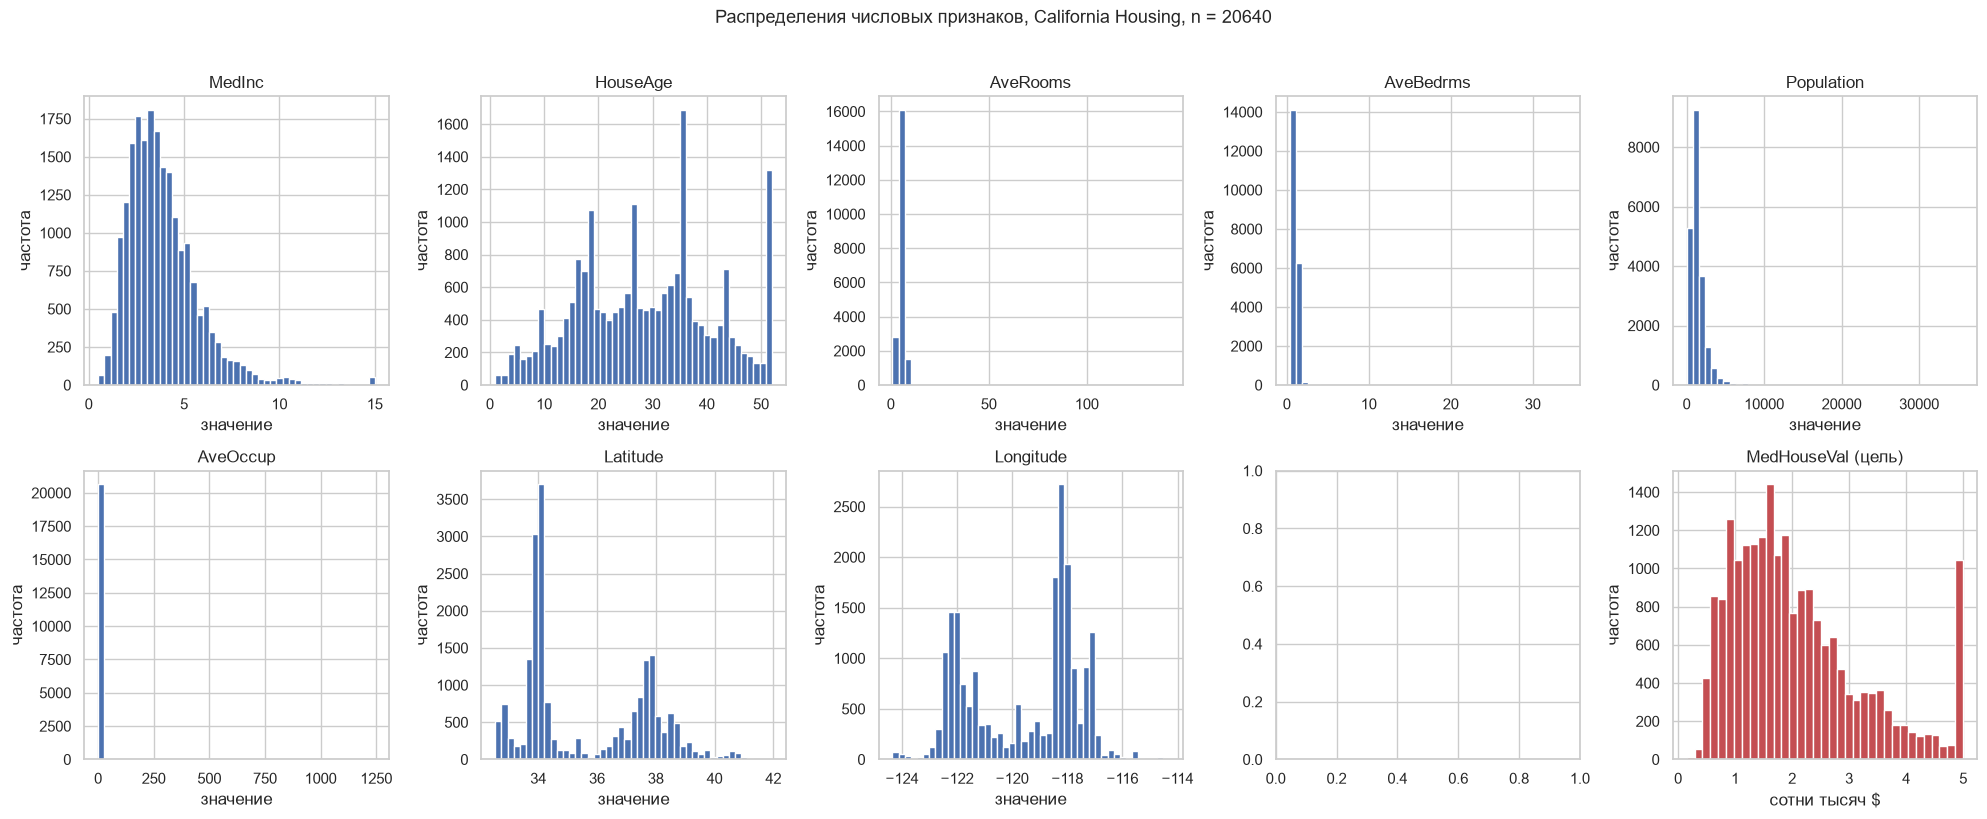

In [17]:
# Смотрим все числовые признаки на одной сетке: так сразу видно, где
# распределение «нормальное», а где это тяжёлый правый хвост.
figure, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.ravel()

for axis, column in zip(axes, feature_columns):
    axis.hist(clean[column], bins=45, color="#4c72b0", edgecolor="white")
    axis.set_title(column)
    axis.set_xlabel("значение")
    axis.set_ylabel("частота")

axes[-1].hist(clean[TARGET], bins=35, color="#c44e52", edgecolor="white")
axes[-1].set_title(f"{TARGET} (цель)")
axes[-1].set_xlabel("сотни тысяч $")
axes[-1].set_ylabel("частота")

figure.suptitle(f"Распределения числовых признаков, California Housing, n = {len(clean)}", y=1.02)
figure.tight_layout()
plt.show()


### География цен

Широта и долгота - самые необычные признаки набора: это не измерения, а
координаты точки на карте. На графике долгота против широты видны два
«пузыря» цен: один на юге (Лос-Анджелес), другой на заливе (Сан-Франциско),
и оба дорогие, тогда как всё остальное побережье дешёвое.

Это важное наблюдение для модели: зависимость цены от координат **нелинейна**
и имеет вид двух пиков, а не одной прямой линии. Линейная регрессия сможет
описать её только приближённо, и это мы увидим в метриках.


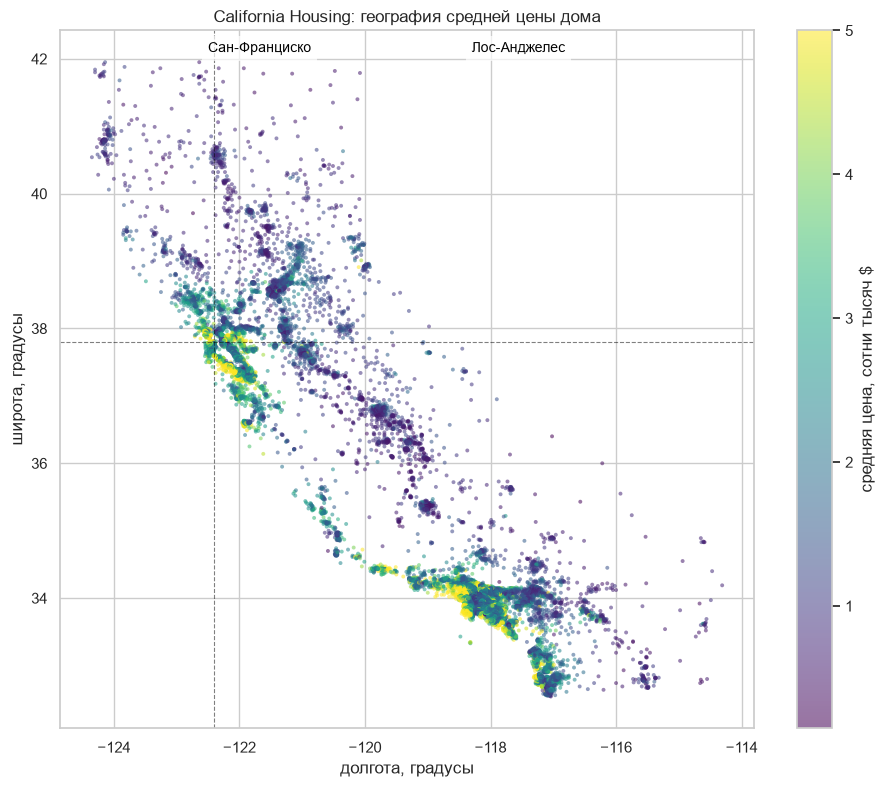

In [18]:
# Карта цен: по горизонтали долгота, по вертикали широта, цвет - средняя цена.
# Так видно структуру, которую не видно ни в одной таблице.
figure, axis = plt.subplots(figsize=(9.5, 8))
scatter = axis.scatter(clean["Longitude"], clean["Latitude"], c=clean[TARGET],
                       s=8, cmap="viridis", alpha=0.55, edgecolor="none")
axis.set_xlabel("долгота, градусы")
axis.set_ylabel("широта, градусы")
axis.set_title("California Housing: география средней цены дома")
axis.axhline(37.8, color="black", linestyle="--", linewidth=0.8, alpha=0.5)
axis.axvline(-122.4, color="black", linestyle="--", linewidth=0.8, alpha=0.5)
axis.text(-122.5, 42.1, "Сан-Франциско", color="black", fontsize=10,
          bbox={"facecolor": "white", "alpha": 0.7, "edgecolor": "none"})
axis.text(-118.3, 42.1, "Лос-Анджелес", color="black", fontsize=10,
          bbox={"facecolor": "white", "alpha": 0.7, "edgecolor": "none"})
figure.colorbar(scatter, ax=axis, label="средняя цена, сотни тысяч $")
figure.tight_layout()
plt.show()


In [19]:
# Регионы .
REGION_BOUNDS = [32.0, 34.0, 36.0, 38.0, 42.0]
REGION_LABELS = ["юг (Лос-Анджелес)", "юго-восток", "залив (Сан-Франциско)", "север"]

region = pd.cut(clean["Latitude"], bins=REGION_BOUNDS, labels=REGION_LABELS)
eda_frame = clean.assign(region=region)

print(eda_frame["region"].value_counts().reindex(REGION_LABELS).to_frame("районов"))
print()
print("медианные значения по регионам:")
eda_frame.groupby("region", observed=True)[
    ["MedInc", "AveRooms", TARGET]].median().reindex(REGION_LABELS).round(3)


                       районов
region                        
юг (Лос-Анджелес)         6310
юго-восток                5506
залив (Сан-Франциско)     5809
север                     3015

медианные значения по регионам:


,MedInc,AveRooms,MedHouseVal
region,,,
юг (Лос-Анджелес),3.730,5.104,1.852
юго-восток,3.455,5.055,1.917
залив (Сан-Франциско),3.681,5.276,2.083
север,3.043,5.570,1.213


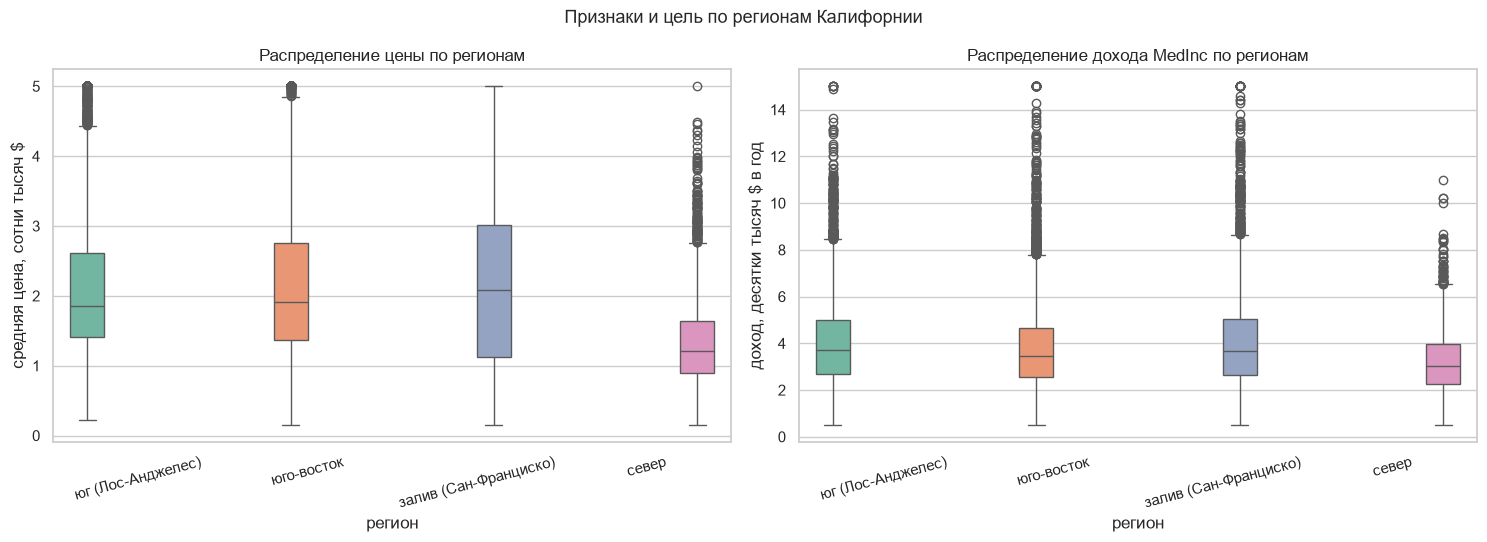

In [20]:
# Ящики с усами по регионам. Разные медианы и разный разброс ящика показывают,
# что регион влияет и на уровень цены, и на её неопределённость.
figure, (axis_price, axis_income) = plt.subplots(1, 2, figsize=(15, 5.5))

sns.boxplot(data=eda_frame, x="region", y=TARGET, hue="region",
            order=REGION_LABELS, palette="Set2", legend=False, ax=axis_price)
axis_price.set_title("Распределение цены по регионам")
axis_price.set_xlabel("регион")
axis_price.set_ylabel("средняя цена, сотни тысяч $")
axis_price.tick_params(axis="x", rotation=15)

sns.boxplot(data=eda_frame, x="region", y="MedInc", hue="region",
            order=REGION_LABELS, palette="Set2", legend=False, ax=axis_income)
axis_income.set_title("Распределение дохода MedInc по регионам")
axis_income.set_xlabel("регион")
axis_income.set_ylabel("доход, десятки тысяч $ в год")
axis_income.tick_params(axis="x", rotation=15)

figure.suptitle("Признаки и цель по регионам Калифорнии")
figure.tight_layout()
plt.show()


### Корреляции и мультиколлинеарность

Матрица корреляций отвечает на два вопроса сразу: что сильно связано с целею
и какие признаки дублируют друг друга.

**Первый вопрос.** С целею сильнее всех связан доход `MedInc` (0.69), а
остальные семь признаков по отдельности почти бесполезны: модуль корреляции
ни у одного не превышает 0.16. Это честный и немного неудобный факт: линейная
модель по одному признаку «координаты» или «число комнат» почти ничего не
предсказывает.

**Второй вопрос.** Два признака дублируют друг друга сильно:

* `Latitude` и `Longitude` коррелируют на **0.93** - координаты по сути одна и
  та же величина, просто записанная дважды;
* `AveRooms` и `AveBedrms` коррелируют на **0.85** - в квартире с большим
  числом комнат почти всегда больше и спален.

Это и есть **мультиколлинеарность**: признаки несут почти одинаковую
информацию, и метод наименьших квадратов при этом теряет устойчивость -
коэффициенты «гуляют», а их сумма остаётся прежней. Мы увидим это в
коэффициентах и учтём при выборе модели.


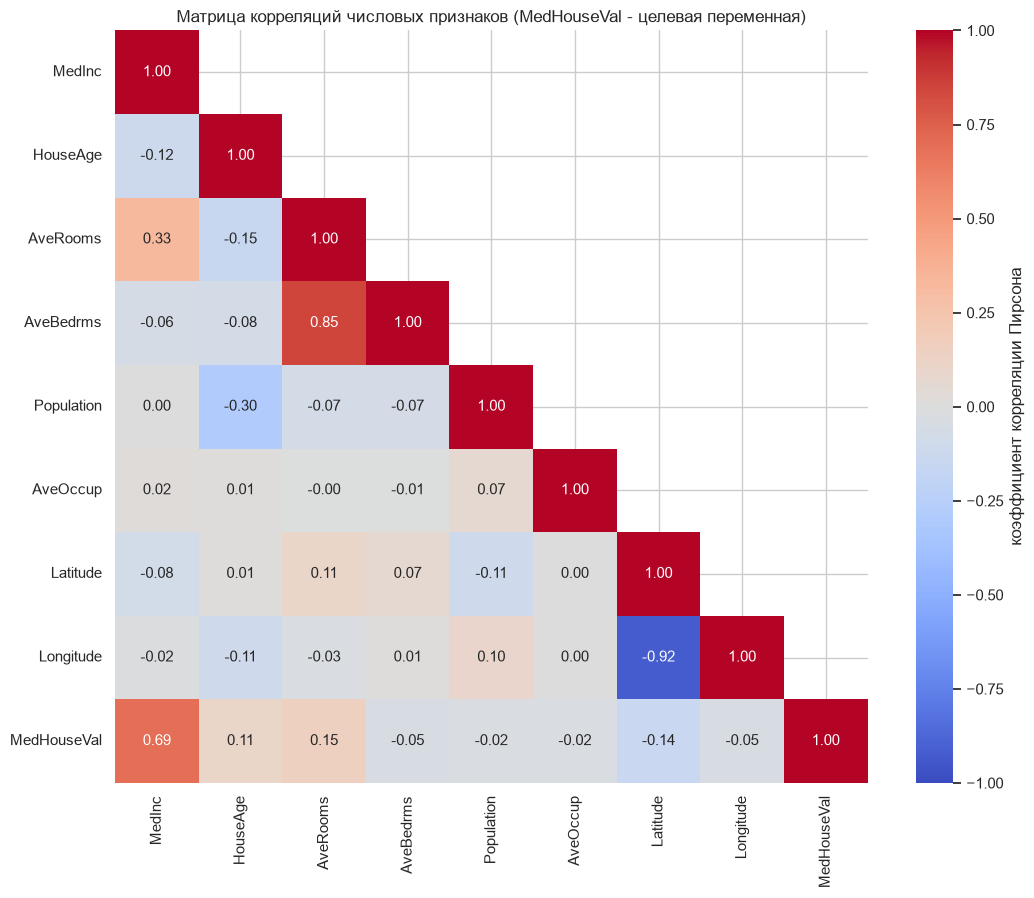

MedInc        0.688075
AveRooms      0.151948
HouseAge      0.105623
AveOccup     -0.023737
Population   -0.024650
Longitude    -0.045967
AveBedrms    -0.046701
Latitude     -0.144160
Name: MedHouseVal, dtype: float64

In [21]:
# Матрица корреляций: сразу видно и сильную связь с целью, и пары признаков,
# которые мешают друг другу.
correlation = clean[numeric_columns].corr()
mask = np.triu(np.ones_like(correlation, dtype=bool), k=1)

figure, axis = plt.subplots(figsize=(11, 9))
sns.heatmap(correlation, annot=True, fmt=".2f", mask=mask,
            cmap="coolwarm", vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "коэффициент корреляции Пирсона"}, ax=axis)
axis.set_title("Матрица корреляций числовых признаков (MedHouseVal - целевая переменная)")
figure.tight_layout()
plt.show()
correlation[TARGET].drop(TARGET).sort_values(ascending=False)



# Каждая клетка отвечает на один вопрос: «насколько сильно меняются две величины 
# одновременно?»
# Тёмно-красный     растут вместе
# Синий             одна растёт, другая падает
# Белый             никак не связаны

In [22]:
# Три вывода из корреляций, на которые будет опираться всё остальное.
# 1) Связь с целью почти есть только у дохода: 0.69 против 0.16 у остальных.
# 2) Latitude и Longitude (0.93) и AveRooms с AveBedrms (0.85) - это пары
#    дубликатов, источник мультиколлинеарности.
# 3) Population сам по себе бесполезен для цены (-0.02), но он участвует в
#    мультиколлинеарных связях - поэтому «лишний» признак не всегда вреден.
strong_pairs = correlation[feature_columns].abs().where(
    np.triu(np.ones(correlation[feature_columns].shape, dtype=bool), k=1)).stack()

print("связь с целевой переменной:")
print(correlation[TARGET].drop(TARGET).sort_values(ascending=False).round(3))
print("\nсамые связанные пары признаков:")
print(strong_pairs.sort_values(ascending=False).head(6).round(3))


связь с целевой переменной:
MedInc        0.688
AveRooms      0.152
HouseAge      0.106
AveOccup     -0.024
Population   -0.025
Longitude    -0.046
AveBedrms    -0.047
Latitude     -0.144
Name: MedHouseVal, dtype: float64

самые связанные пары признаков:
Latitude  Longitude     0.925
AveRooms  AveBedrms     0.848
MedInc    AveRooms      0.327
HouseAge  Population    0.296
          AveRooms      0.153
MedInc    HouseAge      0.119
dtype: float64


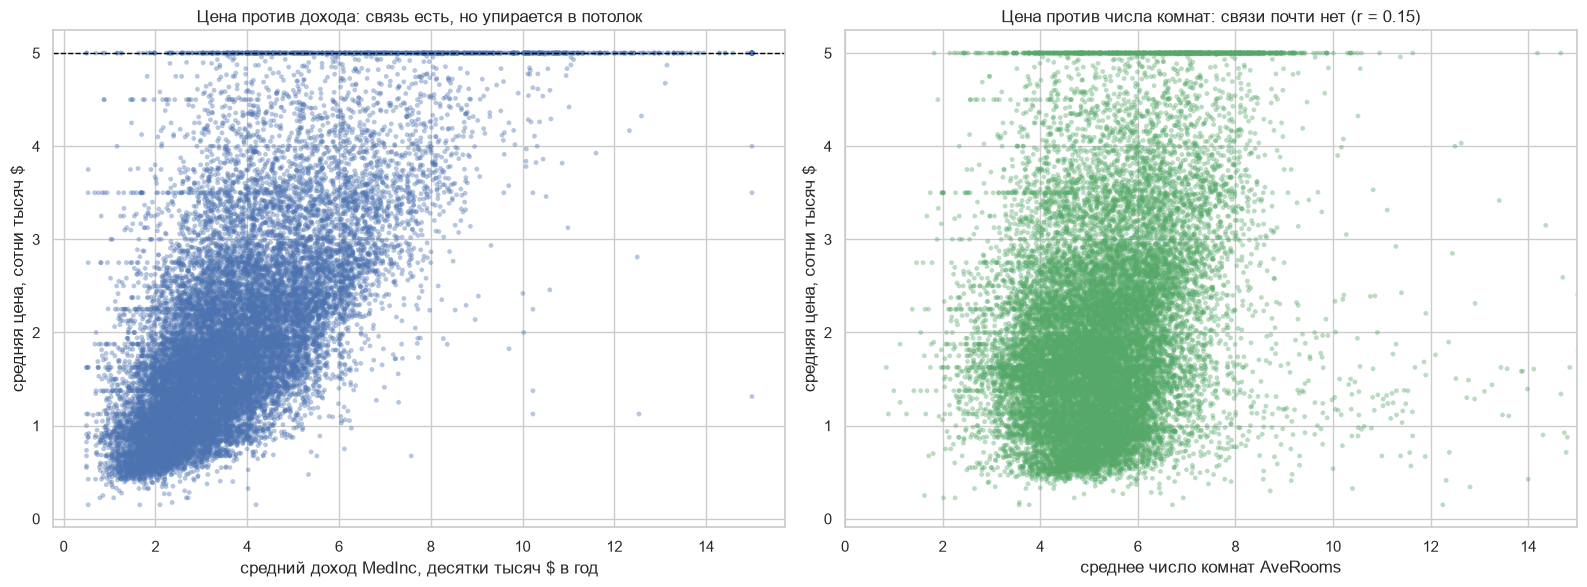

In [23]:
# Два графика одного смысла: связь цены с главным признаком и с признаком,
# который по корреляции бесполезен.
figure, (axis_income, axis_rooms) = plt.subplots(1, 2, figsize=(16, 6))

axis_income.scatter(clean["MedInc"], clean[TARGET], s=12, alpha=0.4,
                    color="#4c72b0", edgecolor="none")
axis_income.set_xlabel("средний доход MedInc, десятки тысяч $ в год")
axis_income.set_ylabel("средняя цена, сотни тысяч $")
axis_income.set_title("Цена против дохода: связь есть, но упирается в потолок")
axis_income.axhline(5.0, color="black", linestyle="--", linewidth=1)

axis_rooms.scatter(clean["AveRooms"], clean[TARGET], s=12, alpha=0.4,
                   color="#55a868", edgecolor="none")
axis_rooms.set_xlim(0, 15)
axis_rooms.set_xlabel("среднее число комнат AveRooms")
axis_rooms.set_ylabel("средняя цена, сотни тысяч $")
axis_rooms.set_title("Цена против числа комнат: связи почти нет (r = 0.15)")

figure.tight_layout()
plt.show()


## 4. Подготовка данных

Два шага, каждый из которых меняет только обучающую выборку:

1. **Разделение** на train / validation / test с фиксированным `random_state`.
   Регрессия - не классификация, стратификация по цели здесь не нужна: цель
   непрерывная, и делить выборки по классам не на чем.
2. **Масштабирование** числовых признаков. Среднее и разброс считаются
   **только на train** - если посчитать их на всей таблице, в модель бы попала
   информация о тесте, и оценка качества оказалась бы завышенной.

Кодировать здесь нечего: все восемь признаков числовые, категорий нет. Это
удобно, но не повод проверять - проверка типов и состава столбцов остаётся в
работе.


In [24]:
# 70 % - обучение, 30 % - поровну на валидацию и тест. Валидация нужна для
# выбора модели, тест - для финальной честной оценки; test_size указан долей от
# промежуточной выборки, поэтому в сумме получается 70/15/15.
X = clean.drop(columns=TARGET)
y = clean[TARGET]

X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.30, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.50, random_state=SEED)

print(f"обучающая:  {len(X_train)} строк · {X_train.shape[1]} признаков")
print(f"валидация:  {len(X_val)} строк")
print(f"тестовая:   {len(X_test)} строк")
print(f"средняя цена в train / val / test: "
      f"{y_train.mean():.4f} / {y_val.mean():.4f} / {y_test.mean():.4f}")
print(f"разброс цены в train: {y_train.std():.4f} (в долларах это "
      f"{y_train.std() * 100:.0f} тысяч)")


обучающая:  14448 строк · 8 признаков
валидация:  3096 строк
тестовая:   3096 строк
средняя цена в train / val / test: 2.0692 / 2.0680 / 2.0660
разброс цены в train: 1.1575 (в долларах это 116 тысяч)


### Зачем здесь масштабирование

В этом датасете разброс признаков различается на порядки:

* `MedInc` - доход в десятках тысяч долларов, стандартное отклонение 1.9;
* `Population` - население в людях, стандартное отклонение около 1140;
* `Latitude` и `Longitude` - градусы с отрицательными значениями, среднее
  широты 35.65 и долготы -119.58.

Для метода наименьших квадратов в замкнутой форме масштаб почти не влияет на
ответ, но он важен по трём причинам. **Первая:** свободный член при
стандартизованных признаках становится средним значением цели, и его
содержательный смысл не теряется. **Вторая:** гребневая регрессия штрафует
коэффициенты, а штраф имеет смысл только у признаков одного масштаба, иначе
штрафуется в первую очередь признак с большими числами. **Третья:** при
численном решении плохо обусловленная система даёт нестабильные коэффициенты.


In [25]:
# Масштабируем по тренировочной выборке. Ключевой момент честности: параметры
# scaler (среднее и стандартное отклонение) считаются ТОЛЬКО на train.
# Валидация и тест только преобразуются функцией transform. Если применить
# fit_transform ко всему датасету, модель получила бы сводную статистику теста -
# это утечка, и оценка качества была бы оптимистичной.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

scaling_check = pd.DataFrame({
    "среднее train (после fit)": X_train_scaled.mean(axis=0).round(6),
    "среднее val (transform)": X_val_scaled.mean(axis=0).round(3),
    "среднее test (transform)": X_test_scaled.mean(axis=0).round(3),
    "ст. отклонение train": X_train_scaled.std(axis=0).round(6),
}, index=X_train.columns)

print("средние после fit_transform(train) равны нулю, а на val и test - нет:")
print("значит, transform не подмешивал статистику других выборок")
scaling_check


средние после fit_transform(train) равны нулю, а на val и test - нет:
значит, transform не подмешивал статистику других выборок


,среднее train (после fit),среднее val (transform),среднее test (transform),ст. отклонение train
MedInc,0.0,-0.021,-0.000,1.0
HouseAge,-0.0,0.016,0.018,1.0
AveRooms,-0.0,-0.033,0.009,1.0
AveBedrms,-0.0,-0.028,0.008,1.0
Population,0.0,0.001,-0.016,1.0
AveOccup,0.0,-0.015,-0.011,1.0
Latitude,-0.0,-0.056,-0.002,1.0
Longitude,-0.0,0.056,-0.008,1.0


## 5. Модель

Линейная регрессия ищет веса $\beta$ и свободный член $\beta_0$, которые
минимизируют сумму квадратов отклонений:

$$
\hat{y} = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p,
\qquad
\min_{\beta}\; \sum_i (y_i - \hat{y}_i)^2
$$

Минимизация по сумме квадратов даёт closed-form решение - отсюда название
«метод наименьших квадратов» (OLS). Модель обучается одной командой `fit` и
не имеет гиперпараметров, требующих подбора, что делает её удобной отправной
точкой: всё, что она не объясняет, - это свойства данных, а не настройка
алгоритма.

Модель собирается в `Pipeline`, чтобы масштабирование гарантированно
обучалось на той выборке, на которой обучается сама регрессия. Для контрольного
эксперимента тот же конструктор умеет собирать полиномиальную и
регуляризованную версии. **Важно:** полиномиальные признаки не делают модель
«нелинейной» - она остаётся линейной по коэффициентам, меняется только базис,
в котором эти коэффициенты ищутся.


In [26]:
def build_model(kind="linear", degree=2, alpha=1.0):
    """Собирает конвейер «преобразования признаков → регрессия» нужного вида.

    kind="linear" - линейная регрессия (базовая модель работы);
    kind="poly"   - линейная регрессия на полиномиальных признаках (контроль нелинейности);
    kind="ridge"  - гребневая регрессия, штраф за величину коэффициентов.
    """
    if kind == "linear":
        steps = [("scaler", StandardScaler()),
                 ("regressor", LinearRegression())]
    elif kind == "poly":
        steps = [("poly", PolynomialFeatures(degree=degree, include_bias=False)),
                 ("scaler", StandardScaler()),
                 ("regressor", LinearRegression())]
    elif kind == "ridge":
        steps = [("scaler", StandardScaler()),
                 ("regressor", Ridge(alpha=alpha, random_state=SEED))]
    else:
        raise ValueError(f"неизвестный вид модели: {kind}")
    return Pipeline(steps)

model = build_model("linear")
model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None


## 6. Обучение

Обучаем на train, смотрим качество на train и на validation. Разница между
ними сразу покажет, не переобучается ли модель: если train заметно лучше
validation, модель запомнила обучающую выборку вместо того, чтобы выучить
закономерность.


In [27]:
# Метрики всегда считаем одним и тем же способом, иначе сравнение бессмысленно.
# MAE - средняя ошибка «в сотнях тысяч долларов», её легко объяснить
#       преподавателю и перевести в деньги.
# RMSE - штрафует крупные промахи сильнее, потому что возводит ошибку в квадрат.
# R² - доля объяснённой дисперсии: 0 - не лучше среднего, 1 - идеально.
# MAPE - ошибка в процентах, нужна как дополнительная точка обзора.
def regression_metrics(y_true, y_pred):
    """Возвращает MAE, RMSE, R² и MAPE одной строкой."""
    return pd.Series({
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R²": r2_score(y_true, y_pred),
        "MAPE, %": mean_absolute_percentage_error(y_true, y_pred) * 100,
    })

print("метрика посчитана для train и для validation - модель обучается на первом")


метрика посчитана для train и для validation - модель обучается на первом


In [28]:
# Обучаем только на train - валидация и тест в fit не участвуют.
model.fit(X_train, y_train)

print("обучение завершено")
print(f"коэффициентов: {len(model.named_steps['regressor'].coef_)} "
      f"(признаков: {X_train.shape[1]})")
print(f"свободный член: {model.named_steps['regressor'].intercept_:.4f}")
print(f"свободный член равен среднему значению цели на train "
      f"({y_train.mean():.4f}) - признаки стандартизованы, и это хороший признак "
      f"корректной модели")

train_scores = regression_metrics(y_train, model.predict(X_train))
val_scores = regression_metrics(y_val, model.predict(X_val))
pd.DataFrame({"обучающая": train_scores, "валидация": val_scores}).round(4)


обучение завершено
коэффициентов: 8 (признаков: 8)
свободный член: 2.0692
свободный член равен среднему значению цели на train (2.0692) - признаки стандартизованы, и это хороший признак корректной модели


,обучающая,валидация
MAE,0.5310,0.5335
RMSE,0.7234,0.7354
R²,0.6093,0.5848
"MAPE, %",31.6032,32.1544


### Честный выбор модели по валидации

Линейная регрессия - модель работы, но прежде чем заявлять результат,
проверим на валидации, не слишком ли мы её упростили. Сравниваем с двумя
кандидатами:

* **полиномиальные признаки** 2-го порядка - та же линейная регрессия, но в
  базисе, где есть квадраты и попарные произведения признаков; позволяет
  описать «два ценовых центра» и насыщение цены у потолка;
* **гребневая регрессия (Ridge)** - штрафует большие коэффициенты, что должно
  помочь при мультиколлинеарности пар широта-долгота и комнаты-спальни; силу
  штрафа $\alpha$ перебираем и тоже выбираем по валидации.

**Правило выбора фиксируется до того, как открыт тест:** выигрывает кандидат
с лучшим R² на валидации; дополнительно мы смотрим, выдаёт ли модель
физически невозможные цены (отрицательные или выше потолка 5.0). Тестовая
выборка в этом сравнении не участвует.


In [29]:
# Подбор кандидата целиком на валидации: тест здесь вообще не открывается.
# Цену физически не может быть ниже минимума и выше максимума, поэтому
# невозможные предсказания считаем отдельной колонкой - метрика R² их не видит.
price_low, price_high = float(y_train.min()), float(y_train.max())

def impossible_count(predictions):
    """Число предсказаний вне диапазона фактических цен."""
    values = np.asarray(predictions)
    return int(((values < price_low) | (values > price_high)).sum())

validation_report = []
models_for_later = {"Линейная регрессия": model}

for alpha in (0.1, 1.0, 10.0, 50.0, 100.0):
    candidate = build_model("ridge", alpha=alpha)
    candidate.fit(X_train, y_train)
    models_for_later[f"Ридж, alpha={alpha:g}"] = candidate
    validation_report.append({
        "модель": f"Ридж, alpha={alpha:g}",
        "R² train": candidate.score(X_train, y_train),
        "R² validation": candidate.score(X_val, y_val),
        "MAE validation": np.mean(np.abs(y_val.to_numpy() - candidate.predict(X_val))),
        "невозможных цен": impossible_count(candidate.predict(X_val)),
    })

validation_report.append({
    "модель": "Линейная регрессия",
    "R² train": model.score(X_train, y_train),
    "R² validation": model.score(X_val, y_val),
    "MAE validation": np.mean(np.abs(y_val.to_numpy() - model.predict(X_val))),
    "невозможных цен": impossible_count(model.predict(X_val)),
})

poly_model = build_model("poly")
poly_model.fit(X_train, y_train)
models_for_later["Полином 2-го порядка"] = poly_model
validation_report.append({
    "модель": "Полином 2-го порядка",
    "R² train": poly_model.score(X_train, y_train),
    "R² validation": poly_model.score(X_val, y_val),
    "MAE validation": np.mean(np.abs(y_val.to_numpy() - poly_model.predict(X_val))),
    "невозможных цен": impossible_count(poly_model.predict(X_val)),
})

validation_table = (pd.DataFrame(validation_report)
                    .sort_values("R² validation", ascending=False)
                    .set_index("модель"))
chosen_name = validation_table.index[0]
chosen_model = models_for_later[chosen_name]

print("выбор сделан по валидации; тестовая выборка не участвовала")
print(f"лучшая по валидации: {chosen_name}")
print(f"признаков после преобразования у выбранной модели: "
      f"{chosen_model[:-1].get_feature_names_out(X_train.columns).size}")

validation_table.round(4)


выбор сделан по валидации; тестовая выборка не участвовала
лучшая по валидации: Полином 2-го порядка
признаков после преобразования у выбранной модели: 44


,R² train,R² validation,MAE validation,невозможных цен
модель,,,,
Полином 2-го порядка,0.6838,0.6699,0.4658,37
"Ридж, alpha=1",0.6093,0.5848,0.5334,50
"Ридж, alpha=0.1",0.6093,0.5848,0.5335,50
Линейная регрессия,0.6093,0.5848,0.5335,50
"Ридж, alpha=10",0.6093,0.5848,0.5334,48
"Ридж, alpha=50",0.6091,0.5847,0.5335,46
"Ридж, alpha=100",0.6086,0.5841,0.5338,43


### Коэффициенты модели

Коэффициенты читаются после стандартизации признаков, поэтому их можно
сравнивать между собой напрямую: это «вклад» признака в отклонение от
среднего в стандартных единицах.

Читать их надо осторожно, и вот почему:

* **Latitude** и **Longitude** получили наибольшие коэффициенты по модулю
  (-0.89 и -0.87). Это не значит «дальше от центра - дешевле на 0.9 сотни
  тысяч за градус»: география нелинейна, и линейная модель описывает её
  усреднённый наклон. Плюс эти два признака коррелируют на 0.93, поэтому
  коэффициенты у них взаимозаменяемы.
* **AveBedrms** вышел положительным (+0.35), а **AveRooms** - отрицательным
  (-0.30), хотя физически больше комнат не может означать дешевле. Это
  классический признак мультиколлинеарности: признаки дублируют друг друга
  (корреляция 0.85), и метод наименьших квадратов «перекладывает» их вклад
  так, чтобы сумма осталась прежней. Вывод: по одному коэффициенту здесь
  судить о влиянии признака нельзя.
* **Population** с коэффициентом -0.001 не даёт почти ничего: по корреляции
  цена от населения не зависит.

Коэффициенты выбранной модели показаны справа: в полиномиальном базисе их 44,
и читать их по отдельности бессмысленно, зато видно, что главный вклад дают
**произведения координат** - то есть модель действительно выучила «две точки
на карте, а не прямую».


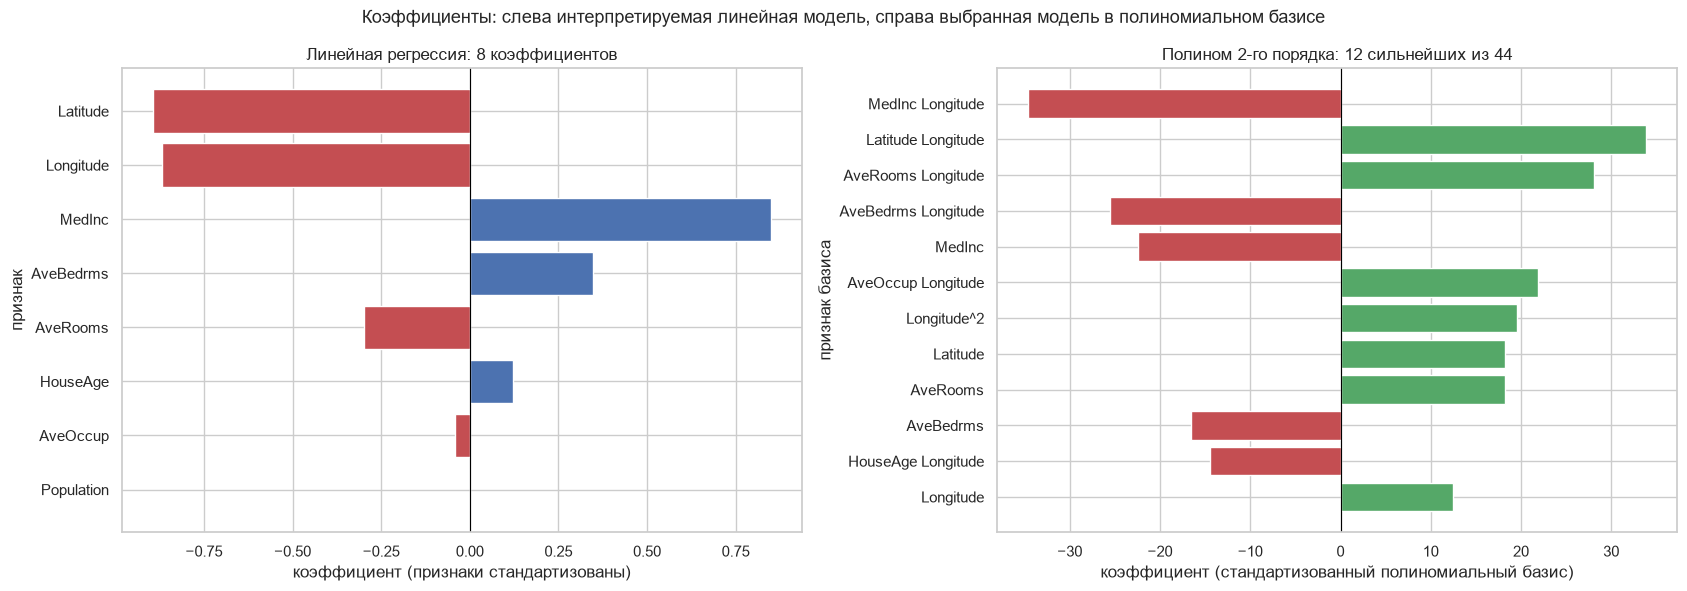

коэффициенты линейной модели:
Latitude     -0.894
Longitude    -0.869
MedInc        0.849
AveBedrms     0.348
AveRooms     -0.300
HouseAge      0.122
AveOccup     -0.042
Population   -0.001
Name: коэффициент, dtype: float64


In [30]:
# Коэффициенты отсортированы по модулю - так сразу видны главные признаки.
# Слева базовая линейная модель (читаемая), справа - выбранная (44 признака,
# читать её коэффициенты по отдельности нельзя, но видно структуру).
coefficients = pd.Series(model.named_steps["regressor"].coef_,
                         index=X_train.columns,
                         name="коэффициент").sort_values(key=abs, ascending=False)

poly_coefficients = pd.Series(chosen_model.named_steps["regressor"].coef_,
                              index=chosen_model.named_steps["poly"].get_feature_names_out(X_train.columns))
poly_top = poly_coefficients.reindex(poly_coefficients.abs().sort_values(ascending=False).index)[:12]

figure, (axis_linear, axis_poly) = plt.subplots(1, 2, figsize=(17, 6))

colors = ["#c44e52" if value < 0 else "#4c72b0" for value in coefficients]
axis_linear.barh(coefficients.index, coefficients.values, color=colors)
axis_linear.axvline(0, color="black", linewidth=0.8)
axis_linear.set_xlabel("коэффициент (признаки стандартизованы)")
axis_linear.set_ylabel("признак")
axis_linear.set_title("Линейная регрессия: 8 коэффициентов")
axis_linear.invert_yaxis()

colors = ["#c44e52" if value < 0 else "#55a868" for value in poly_top]
axis_poly.barh(poly_top.index, poly_top.values, color=colors)
axis_poly.axvline(0, color="black", linewidth=0.8)
axis_poly.set_xlabel("коэффициент (стандартизованный полиномиальный базис)")
axis_poly.set_ylabel("признак базиса")
axis_poly.set_title(f"{chosen_name}: 12 сильнейших из {len(poly_coefficients)}")
axis_poly.invert_yaxis()

figure.suptitle("Коэффициенты: слева интерпретируемая линейная модель, "
                "справа выбранная модель в полиномиальном базисе")
figure.tight_layout()
plt.show()

print("коэффициенты линейной модели:")
print(coefficients.round(3))


## 7. Оценка качества

Метрики снимаются на тестовой выборке, которая не участвовала ни в обучении,
ни в выборе модели. Одна метрика сама по себе ничего не доказывает, поэтому
рядом обязательно считается **базовая линия** - модель, которая вообще ничего
не знает о данных и всегда предсказывает одно и то же число. Если наша модель
не выигрывает у неё, работа бессмысленна.

### Почему приводим и MAE, и RMSE

* **MAE** отвечает на вопрос «на сколько в среднем ошибаемся в цене» - это
  понятная человеку величина, устойчивая к выбросам. Единицы здесь читаются
  прямо: 0.46 сотни тысяч долларов это около 46 тысяч долларов на дом.
* **RMSE** дополнительно штрафует крупные промахи, потому что возводит ошибку
  в квадрат. На этом датасете у дорогих районов ошибка в разы больше, чем у
  дешёвых, поэтому **RMSE систематически завышает впечатление от модели**.
* **MAPE** в процентах требует осторожности: самые дешёвые дома стоят 15-20
  тысяч долларов, и небольшая ошибка в абсолютных единицах даёт там огромный
  процент. Поэтому MAPE приводится как дополнительная точка обзора, а выводы
  формулируются по MAE и RMSE.


In [31]:
# Базовая линия: модель, которая игнорирует все признаки и всегда выдаёт
# одно число. Если наша регрессия не лучше неё, она не выучила ничего.
# Обучаем на train - по правилам честной оценки базовая линия тоже не должна
# видеть тест.
dummy_mean = DummyRegressor(strategy="mean").fit(X_train, y_train)
dummy_median = DummyRegressor(strategy="median").fit(X_train, y_train)

dummy_mean_scores = regression_metrics(y_test, dummy_mean.predict(X_test))
dummy_median_scores = regression_metrics(y_test, dummy_median.predict(X_test))

print(f"предсказание базовой линии (среднее цены в train): {y_train.mean():.4f} "
      f"({y_train.mean() * 100:.0f} тысяч $)")
print(f"предсказание базовой линии (медиана цены в train): {np.median(y_train):.4f} "
      f"({np.median(y_train) * 100:.0f} тысяч $)")
pd.DataFrame({"базовая: среднее": dummy_mean_scores,
              "базовая: медиана": dummy_median_scores}).round(4)


предсказание базовой линии (среднее цены в train): 2.0692 (207 тысяч $)
предсказание базовой линии (медиана цены в train): 1.7930 (179 тысяч $)


,базовая: среднее,базовая: медиана
MAE,0.9118,0.8820
RMSE,1.1499,1.1819
R²,-0.0000,-0.0563
"MAPE, %",62.4339,52.7248


In [32]:
# Тестовая выборка открывается здесь - в первый и последний раз.
# Оцениваем выбранную по валидации модель.
test_predictions = chosen_model.predict(X_test)
test_scores = regression_metrics(y_test, test_predictions)

print(f"выбранная по валидации модель: {chosen_name}")
print(f"тестовая выборка: {len(y_test)} строк")
print()
print("Метрики на тесте:")
print(test_scores.round(4))
print()
print(f"типичная ошибка - {test_scores['MAE']:.3f} сотни тысяч долларов "
      f"(около {test_scores['MAE'] * 100:.0f} тысяч $ на дом)")
print(f"модель объясняет {test_scores['R²']:.1%} изменчивости цены")
print(f"разброс самой цели на тесте: {y_test.std():.3f} - модель ошибается "
      f"в {y_test.std() / test_scores['MAE']:.2f} раза тише, чем цена разбросана вокруг среднего")


выбранная по валидации модель: Полином 2-го порядка
тестовая выборка: 3096 строк

Метрики на тесте:
MAE         0.4608
RMSE        0.6928
R²          0.6371
MAPE, %    26.5346
dtype: float64

типичная ошибка - 0.461 сотни тысяч долларов (около 46 тысяч $ на дом)
модель объясняет 63.7% изменчивости цены
разброс самой цели на тесте: 1.150 - модель ошибается в 2.50 раза тише, чем цена разбросана вокруг среднего


In [33]:
# Итоговая сверка: все обученные модели и базовые линии один раз проверяются
# на тесте. Выбор модели при этом уже сделан выше - по валидации, поэтому это
# финальная сверка, а не подбор по тесту.
final_rows = []
for name, estimator in [("Базовая: среднее", dummy_mean),
                        ("Базовая: медиана", dummy_median),
                        *models_for_later.items()]:
    predictions = estimator.predict(X_test)
    scores = regression_metrics(y_test, predictions)
    final_rows.append({"Модель": name, "MAE": scores["MAE"], "RMSE": scores["RMSE"],
                       "R²": scores["R²"], "MAPE, %": scores["MAPE, %"],
                       "невозможных цен": impossible_count(predictions)})

final_table = pd.DataFrame(final_rows).set_index("Модель")
final_table["MAE лучше базовой, раз"] = (final_table.loc["Базовая: среднее", "MAE"] /
                                          final_table["MAE"]).round(2)
final_table["RMSE лучше базовой, раз"] = (final_table.loc["Базовая: среднее", "RMSE"] /
                                           final_table["RMSE"]).round(2)

print("все модели на тестовой выборке (n = %d)" % len(y_test))
final_table.sort_values("R²", ascending=False).round(4)


все модели на тестовой выборке (n = 3096)


,MAE,RMSE,R²,"MAPE, %",невозможных цен,"MAE лучше базовой, раз","RMSE лучше базовой, раз"
Модель,,,,,,,
Полином 2-го порядка,0.4608,0.6928,0.6371,26.5346,36,1.98,1.66
"Ридж, alpha=100",0.5211,0.7190,0.6091,31.3330,36,1.75,1.60
"Ридж, alpha=50",0.5209,0.7199,0.6081,31.3288,39,1.75,1.60
"Ридж, alpha=10",0.5210,0.7210,0.6069,31.3398,41,1.75,1.59
"Ридж, alpha=1",0.5210,0.7213,0.6066,31.3454,42,1.75,1.59
"Ридж, alpha=0.1",0.5210,0.7213,0.6066,31.3460,42,1.75,1.59
Линейная регрессия,0.5210,0.7213,0.6066,31.3461,42,1.75,1.59
Базовая: среднее,0.9118,1.1499,-0.0000,62.4339,0,1.00,1.00
Базовая: медиана,0.8820,1.1819,-0.0563,52.7248,0,1.03,0.97


In [34]:
# Ответ на главный вопрос работы: во сколько раз модель лучше базовой линии.
# Сравнивать надо по MAE (типичная ошибка) и по RMSE (худшие случаи) сразу:
# выигрыш по одной метрике при провале по другой - это не победа.
# Рядом же - честная цена усложнения: сколько потеряла базовая линейная модель.
linear_row = final_table.loc["Линейная регрессия"]
baseline_row = final_table.loc["Базовая: среднее"]
median_row = final_table.loc["Базовая: медиана"]

mae_gain = baseline_row["MAE"] / test_scores["MAE"]
rmse_gain = baseline_row["RMSE"] / test_scores["RMSE"]

print(f"выбранная модель ({chosen_name}) против базовой линии по среднему:")
print(f"MAE:  {baseline_row['MAE']:.3f} -> {test_scores['MAE']:.3f}  "
      f"(в {mae_gain:.2f} раза меньше ошибки)")
print(f"RMSE: {baseline_row['RMSE']:.3f} -> {test_scores['RMSE']:.3f}  "
      f"(в {rmse_gain:.2f} раза меньше ошибки)")
print(f"R²:   {baseline_row['R²']:.3f} -> {test_scores['R²']:.3f}")
print()
print(f"медиана как базовая линия чуть лучше среднего по MAE ({median_row['MAE']:.3f}), "
      f"но хуже по RMSE ({median_row['RMSE']:.3f}) и даёт отрицательный R² "
      f"({median_row['R²']:.3f})")
print(f"цена усложнения: выбранная модель лучше базовой линейной на "
      f"{1 - test_scores['MAE'] / linear_row['MAE']:.1%} по MAE и на "
      f"{test_scores['R²'] - linear_row['R²']:.3f} по R² "
      f"({linear_row['R²']:.3f} -> {test_scores['R²']:.3f})")


выбранная модель (Полином 2-го порядка) против базовой линии по среднему:
MAE:  0.912 -> 0.461  (в 1.98 раза меньше ошибки)
RMSE: 1.150 -> 0.693  (в 1.66 раза меньше ошибки)
R²:   -0.000 -> 0.637

медиана как базовая линия чуть лучше среднего по MAE (0.882), но хуже по RMSE (1.182) и даёт отрицательный R² (-0.056)
цена усложнения: выбранная модель лучше базовой линейной на 11.6% по MAE и на 0.031 по R² (0.607 -> 0.637)


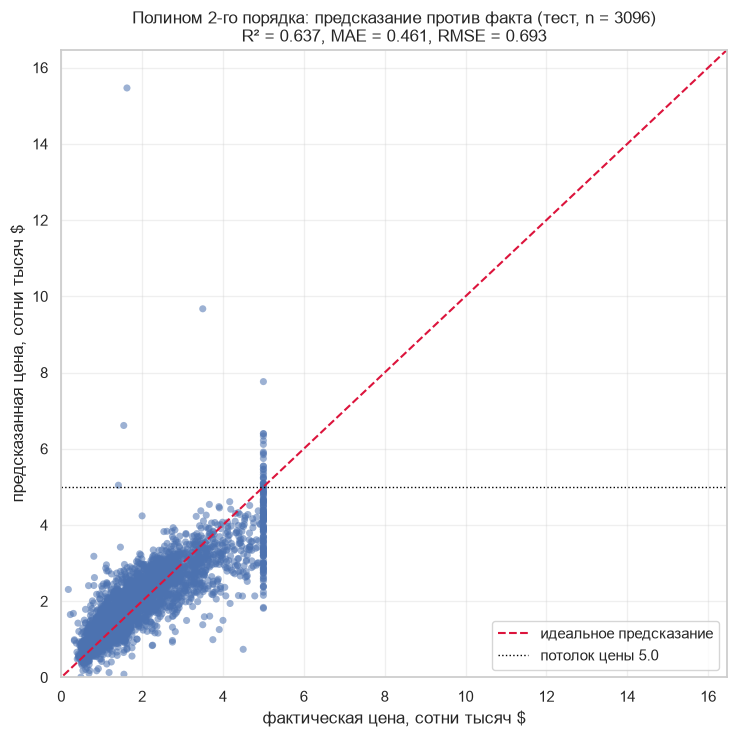

In [35]:
# Главный график регрессии: фактические значения против предсказанных.
# Точки должны лежать вдоль диагонали; если они вытянуты вдоль неё с обеих
# сторон - ошибки случайны и модель работает честно. Здесь видно и другое:
# в верхней части точки систематически ниже диагонали, то есть самые дорогие
# районы модель занижает.
figure, axis = plt.subplots(figsize=(7.5, 7.5))
axis.scatter(y_test, test_predictions, s=26, alpha=0.55, color="#4c72b0", edgecolor="none")

limits = [float(min(y_test.min(), test_predictions.min())) - 1,
          float(max(y_test.max(), test_predictions.max())) + 1]
axis.plot(limits, limits, "--", color="crimson", linewidth=1.5,
          label="идеальное предсказание")
axis.set_xlim(0, limits[1])
axis.set_ylim(0, limits[1])
axis.axhline(5.0, color="black", linestyle=":", linewidth=1, label="потолок цены 5.0")
axis.set_xlabel("фактическая цена, сотни тысяч $")
axis.set_ylabel("предсказанная цена, сотни тысяч $")
axis.set_title(f"{chosen_name}: предсказание против факта (тест, n = {len(y_test)})\n"
               f"R² = {test_scores['R²']:.3f}, MAE = {test_scores['MAE']:.3f}, "
               f"RMSE = {test_scores['RMSE']:.3f}")
axis.legend()
axis.grid(alpha=0.3)
figure.tight_layout()
plt.show()


### Разбор ошибок

Остаток - это разница между фактом и предсказанием, `residual = y - ŷ`.
Смотреть на них нужно обязательно: метрики дают одно число, а остатки
показывают, **где** модель ошибается.

Что ищем:

* **смещение** - если средний остаток не ноль, модель систематически
  занижает или завышает ответ;
* **система** - если остаток предсказуем по какому-то признаку, значит модель
  чего-то не учитывает;
* **форма распределения** - симметричный колокол означает, что остатки ведут
  себя как шум, и доверительные интервалы можно считать по теории;
* **зависимость от предсказания** - если разброс растёт вместе с
  предсказанием, это гетероскедастичность: одна дисперсия на все случаи не
  работает.


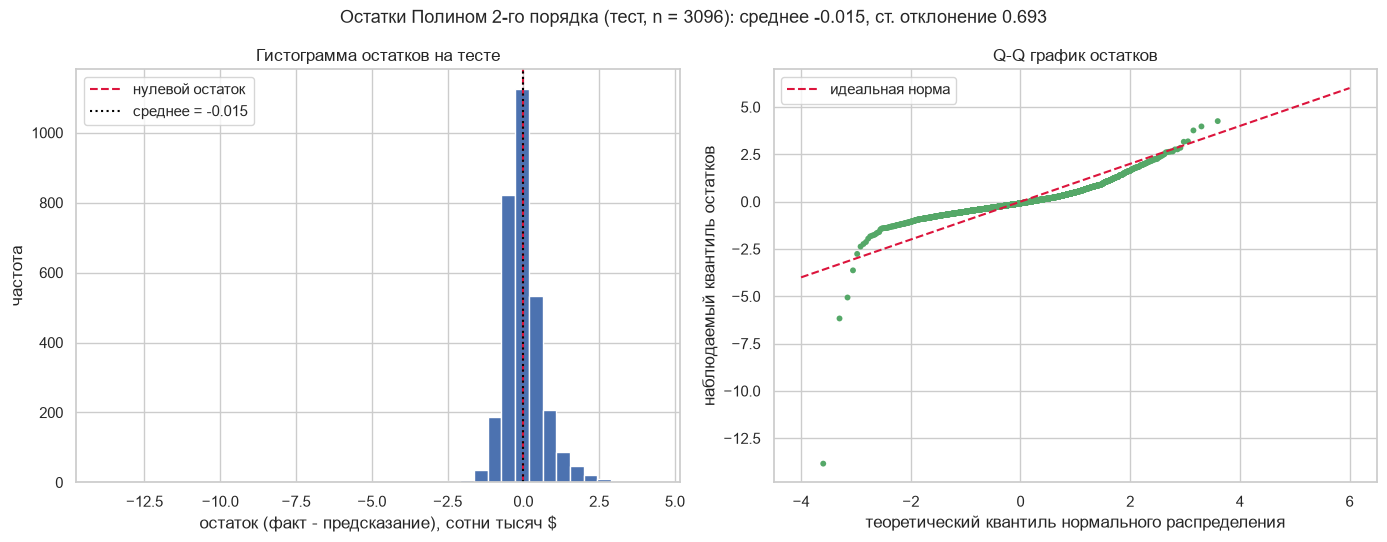

In [36]:
# Слева гистограмма остатков, справа Q-Q график: если точки Q-Q ложатся на
# прямую, остатки нормальные. Здесь они заметно отклоняются - левый хвост
# заметно тяжелее нормального, о чём честно скажем в выводах.
residuals = y_test - test_predictions
theoretical_quantiles = np.array([
    NormalDist().inv_cdf((rank - 0.5) / len(residuals))
    for rank in range(1, len(residuals) + 1)
])

figure, (axis_hist, axis_qq) = plt.subplots(1, 2, figsize=(14, 5.5))
axis_hist.hist(residuals, bins=40, color="#4c72b0", edgecolor="white")
axis_hist.axvline(0, color="crimson", linestyle="--", label="нулевой остаток")
axis_hist.axvline(residuals.mean(), color="black", linestyle=":",
                  label=f"среднее = {residuals.mean():.3f}")
axis_hist.set_xlabel("остаток (факт - предсказание), сотни тысяч $")
axis_hist.set_ylabel("частота")
axis_hist.set_title("Гистограмма остатков на тесте")
axis_hist.legend()

axis_qq.scatter(theoretical_quantiles, np.sort(residuals), s=18,
                color="#55a868", edgecolor="none")
qq_low, qq_high = -4, 6
axis_qq.plot([qq_low, qq_high], [qq_low, qq_high], "--", color="crimson",
             label="идеальная норма")
axis_qq.set_xlabel("теоретический квантиль нормального распределения")
axis_qq.set_ylabel("наблюдаемый квантиль остатков")
axis_qq.set_title("Q-Q график остатков")
axis_qq.legend()

figure.suptitle(f"Остатки {chosen_name} (тест, n = {len(residuals)}): "
                f"среднее {residuals.mean():.3f}, "
                f"ст. отклонение {residuals.std():.3f}")
figure.tight_layout()
plt.show()


In [37]:
# Численное подтверждение того, что видно на графиках. Отрицательный эксцесс
# означает асимметрию: левый хвост (модель предсказала намного дороже факта)
# заметно длиннее правого.
residuals_series = pd.Series(residuals)
residual_stats = pd.Series({
    "среднее (смещение)": residuals_series.mean(),
    "медиана": residuals_series.median(),
    "ст. отклонение": residuals_series.std(),
    "минимум": residuals_series.min(),
    "максимум": residuals_series.max(),
    "асимметрия": residuals_series.skew(),
    "эксцесс": residuals_series.kurt(),
})
residual_stats.round(3)


среднее (смещение)    -0.015
медиана               -0.090
ст. отклонение         0.693
минимум              -13.842
максимум               4.255
асимметрия            -2.072
эксцесс               56.283
dtype: float64

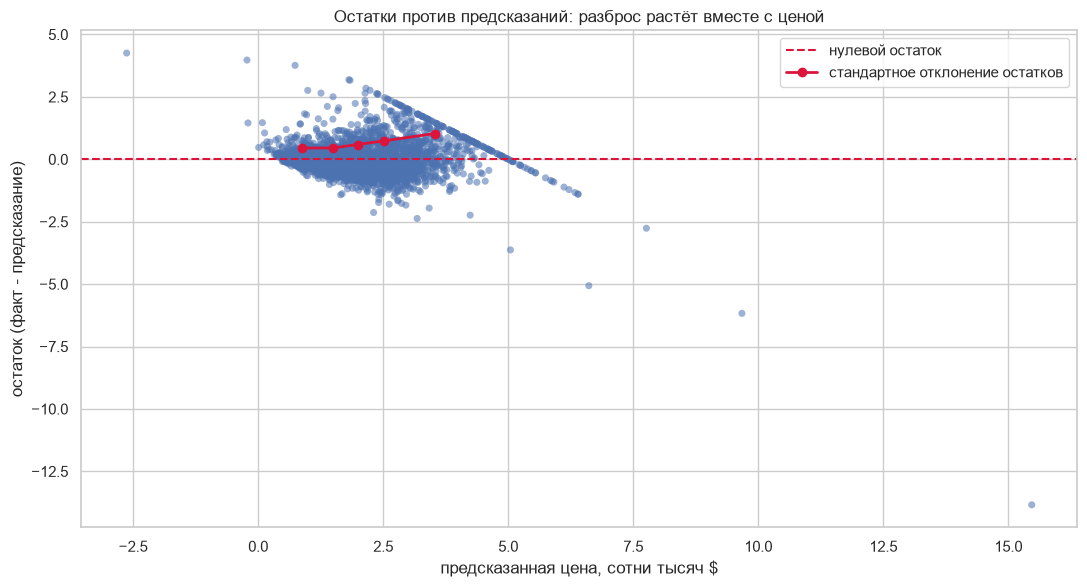

разброс остатков растёт в 2.28 раза от самых дешёвых предсказаний к самым дорогим


,среднее предсказание,средний остаток,ст. отклонение остатка,n
0,0.872,0.085,0.451,620
1,1.496,-0.089,0.453,619
2,1.990,-0.097,0.592,619
3,2.521,-0.064,0.740,619
4,3.526,0.093,1.030,619


In [38]:
# Главный недостаток модели на этих данных - гетероскедастичность: чем дороже
# дом, тем крупнее ошибка. Линейная модель описывает среднее, но не описывает
# разброс вокруг него.
figure, axis = plt.subplots(figsize=(11, 6))
axis.scatter(test_predictions, residuals, s=26, alpha=0.55,
             color="#4c72b0", edgecolor="none")
axis.axhline(0, color="crimson", linestyle="--", label="нулевой остаток")

# Разброс по квинтилям предсказаний показывает тренд без «помощи» scipy.
# Важная деталь: остатки и квинтили строим в одном и том же порядке строк.
# Если у них будут разные индексы, группировка перемешает строки между собой
# и даст бессмысленные числа (корзины неравного размера, случайные средние).
predictions_in_order = np.asarray(test_predictions)
residuals_in_order = np.asarray(residuals)
quantiles = pd.Series(pd.qcut(predictions_in_order, 5, labels=False, duplicates="drop"))
residuals_ordered = pd.Series(residuals_in_order)

spread_by_bucket = residuals_ordered.groupby(quantiles).std()
bucket_centers = pd.Series(predictions_in_order).groupby(quantiles).mean()
axis.plot(bucket_centers, spread_by_bucket, "o-", color="crimson",
          linewidth=2, label="стандартное отклонение остатков")

axis.set_xlabel("предсказанная цена, сотни тысяч $")
axis.set_ylabel("остаток (факт - предсказание)")
axis.set_title("Остатки против предсказаний: разброс растёт вместе с ценой")
axis.legend()
figure.tight_layout()
plt.show()

spread_table = pd.DataFrame({
    "среднее предсказание": bucket_centers,
    "средний остаток": residuals_ordered.groupby(quantiles).mean(),
    "ст. отклонение остатка": spread_by_bucket,
    "n": residuals_ordered.groupby(quantiles).size(),
}).round(3)
print(f"разброс остатков растёт в "
      f"{spread_table['ст. отклонение остатка'].iloc[-1] / spread_table['ст. отклонение остатка'].iloc[0]:.2f} раза "
      f"от самых дешёвых предсказаний к самым дорогим")
spread_table


In [39]:
# Численные показатели гетероскедастичности: связь ошибки с предсказанием и
# доля крупных промахов.
error_report = pd.Series({
    "связь |остаток| и предсказание": np.corrcoef(np.abs(residuals), test_predictions)[0, 1],
    "RMSE делённый на MAE": test_scores["RMSE"] / test_scores["MAE"],
    "доля остатков больше 0.5": float((np.abs(residuals) > 0.5).mean()),
    "максимальный промах, сотни тысяч $": float(np.abs(residuals).max()),
    "доля точных попаданий (меньше 0.1)": float((np.abs(residuals) < 0.1).mean()),
})
error_report.round(4)


связь |остаток| и предсказание         0.3713
RMSE делённый на MAE                   1.5033
доля остатков больше 0.5               0.3291
максимальный промах, сотни тысяч $    13.8417
доля точных попаданий (меньше 0.1)     0.1499
dtype: float64

In [40]:
# Где именно модель ошибается: разбиваем тест по цене и по доходу. Видно две
# разные проблемы - систематическое завышение дешёвых домов и занижение домов
# у потолка, где исходные данные обрезаны сверху.
price_groups = pd.cut(y_test, [0, 1, 2, 3, 5.01],
                      labels=["до 1.0", "1-2", "2-3", "3-5 (до потолка)"])
income_groups = pd.qcut(X_test["MedInc"], 5, labels=False, duplicates="drop")

by_price = pd.DataFrame({
    "n": residuals_series.groupby(price_groups, observed=True).size(),
    "средний остаток": residuals_series.groupby(price_groups, observed=True).mean(),
    "ст. отклонение": residuals_series.groupby(price_groups, observed=True).std(),
})
by_income = pd.DataFrame({
    "средний MedInc": X_test["MedInc"].groupby(income_groups).mean(),
    "средний остаток": residuals_series.groupby(income_groups).mean(),
    "ст. отклонение": residuals_series.groupby(income_groups).std(),
})

print("остатки по корзинам цены (сотни тысяч $):")
print(by_price.round(3))
print()
print("остатки по квинтилям дохода:")
print(by_income.round(3))


остатки по корзинам цены (сотни тысяч $):
                     n  средний остаток  ст. отклонение
MedHouseVal                                            
до 1.0             535           -0.243           0.364
1-2               1261           -0.233           0.617
2-3                727           -0.018           0.477
3-5 (до потолка)   573            0.684           0.837

остатки по квинтилям дохода:
        средний MedInc  средний остаток  ст. отклонение
MedInc                                                 
0                1.832            0.028           0.528
1                2.741           -0.038           0.540
2                3.511           -0.010           0.640
3                4.478           -0.092           0.922
4                6.827            0.038           0.751


In [41]:
# Разбор конкретных ошибок: в каких районах модель ошибается сильнее всего.
# Так ошибки перестают быть абстрактным числом.
error_details = pd.DataFrame({
    "факт": y_test.to_numpy(),
    "предсказание": test_predictions,
    "остаток": residuals,
    "MedInc, тыс. $": X_test["MedInc"].to_numpy(),
    "Latitude": X_test["Latitude"].to_numpy(),
    "Longitude": X_test["Longitude"].to_numpy(),
    "AveRooms": X_test["AveRooms"].to_numpy(),
})
worst_predictions = error_details.loc[
    error_details["остаток"].abs().sort_values(ascending=False).index]

print("десять худших предсказаний:")
worst_predictions.head(10).round(3)


десять худших предсказаний:


,факт,предсказание,остаток,"MedInc, тыс. $",Latitude,Longitude,AveRooms
1979,1.625,15.467,-13.842,4.625,38.80,-120.08,132.533
1566,3.500,9.672,-6.172,15.000,37.74,-121.96,22.222
9172,1.546,6.611,-5.065,4.239,34.47,-118.59,5.124
12104,1.625,-2.630,4.255,1.625,33.97,-117.33,7.600
4093,3.750,-0.224,3.974,0.536,34.16,-118.42,9.000
19542,4.500,0.737,3.763,1.768,37.63,-120.92,5.000
11833,1.413,5.043,-3.630,4.082,39.28,-120.18,39.756
12069,5.000,1.813,3.187,4.239,33.83,-117.55,7.723
17306,5.000,1.837,3.163,2.728,34.38,-119.55,5.574
4245,5.000,2.153,2.847,4.083,34.13,-118.32,7.030


In [42]:
# Последний вопрос к модели, который R² не задаёт: физически ли возможны её
# предсказания? Цена не может быть отрицательной и не может превышать потолок
# 5.0. Такая же проверка была и на валидации - она повлияла на выбор модели.
price_low, price_high = float(clean[TARGET].min()), float(clean[TARGET].max())

def impossible_share(predictions):
    """Доля предсказаний вне диапазона фактических цен."""
    values = np.asarray(predictions)
    outside = (values < price_low) | (values > price_high)
    return pd.Series({"минимум": values.min(), "максимум": values.max(),
                      "вне диапазона": int(outside.sum()),
                      "доля, %": outside.mean() * 100})

print(f"фактический диапазон цены: {price_low:.2f} - {price_high:.2f}")
pd.DataFrame({
    "Линейная": impossible_share(model.predict(X_test)),
    chosen_name: impossible_share(test_predictions),
}).T.round(3)


фактический диапазон цены: 0.15 - 5.00


,минимум,максимум,вне диапазона,"доля, %"
Линейная,-0.587,11.507,42.0,1.357
Полином 2-го порядка,-2.630,15.467,36.0,1.163


In [43]:
# Проверяем гипотезу: невозможные предсказания вызваны не моделью, а
# неправдоподобными входными средними - районами, где на домохозяйство
# приходится 132 комнаты. Если так, виноваты данные, а не алгоритм.
flagged = (X_test["AveRooms"] > 20) | (X_test["AveBedrms"] > 20) | (X_test["AveOccup"] > 20)
outside = (test_predictions < price_low) | (test_predictions > price_high)

print(f"строк с неправдоподобными средними в тесте: {int(flagged.sum())}")
print(f"невозможных предсказаний всего: {int(outside.sum())}")
print(f"из них вызваны неправдоподобными средними: {int((flagged & outside).sum())}")
print()
print("вывод: часть выбросов мы оставили осознанно, и именно они дают")
print("физически невозможные предсказации. Удалять их ради красоты метрик")
print("нельзя - это была бы подгонка данных под модель.")


строк с неправдоподобными средними в тесте: 13
невозможных предсказаний всего: 36
из них вызваны неправдоподобными средними: 5

вывод: часть выбросов мы оставили осознанно, и именно они дают
физически невозможные предсказации. Удалять их ради красоты метрик
нельзя - это была бы подгонка данных под модель.


### Идеальные данные для прогноза

Типичный образец датасета - медианная строка: по каждому из восьми признаков
взята медиана всех 20640 строк. Это свод типичных значений, а не конкретный
район, и на таком спокойном входе модель отвечает без экстремальных условий.
Сравниваем предсказание с фактической медианной ценой из данных: разница
показывает, куда модель смещается на типичном образце.


In [44]:
# Медианная строка.
median_features = X.median()
median_row = median_features.to_frame().T

# Предсказание.
median_prediction = float(chosen_model.predict(median_row)[0])
median_fact = float(y.median())
median_gap = median_prediction - median_fact

print(f"модель: {chosen_name}")
print("типичный образец - медианная строка датасета:")
print(pd.DataFrame({"значение": median_features}).round(4))
print()
print(f"предсказание модели: {median_prediction:.4f} сотни тысяч $ "
      f"(около {median_prediction * 100:.0f} тысяч $)")
print(f"факт (медиана цены в данных): {median_fact:.4f} сотни тысяч $ "
      f"(около {median_fact * 100:.0f} тысяч $)")
print(f"разница (предсказание - факт): {median_gap:+.4f} сотни тысяч $ "
      f"({median_gap * 100:+.0f} тысяч $)")

модель: Полином 2-го порядка
типичный образец - медианная строка датасета:
             значение
MedInc         3.5348
HouseAge      29.0000
AveRooms       5.2291
AveBedrms      1.0488
Population  1166.0000
AveOccup       2.8181
Latitude      34.2600
Longitude   -118.4900

предсказание модели: 1.9641 сотни тысяч $ (около 196 тысяч $)
факт (медиана цены в данных): 1.7970 сотни тысяч $ (около 180 тысяч $)
разница (предсказание - факт): +0.1671 сотни тысяч $ (+17 тысяч $)


### Расчёт по своим данным

Модель отвечает на конкретный запрос: вводим значения восьми признаков
с клавиатуры, получаем предсказание цены в сотнях тысяч долларов. Порядок
признаков и сама модель - те же, что в разделах 6-7, ничего не переобучается.

Если ноутбук запускается программно и клавиатуры нет, ввод перехватывается,
и расчёт спокойно продолжается на медианной строке - ячейка не падает.


In [45]:
# Ввод данных. Подсказки - в тех же единицах, что и в таблице признаков.
FEATURE_HINTS = {
    "MedInc": "десятки тысяч $ в год",
    "HouseAge": "годы",
    "AveRooms": "комнат на домохозяйство",
    "AveBedrms": "спален на домохозяйство",
    "Population": "человек",
    "AveOccup": "жильцов на домохозяйство",
    "Latitude": "градусы, для Калифорнии около 34-42",
    "Longitude": "градусы, западные - со знаком минус",
}


def ask_number(name, fallback):
    """Спрашивает одно вещественное число признака с клавиатуры.

    Возвращает число; если ввода нет или введено не число, возвращает
    fallback (значение медианной строки). Единицы - как у признака.
    """
    hint = FEATURE_HINTS.get(name, name)
    while True:
        try:
            raw = input(f"{name} ({hint}): ")
        except (EOFError, OSError):
            raw = None
        except Exception as error:
            # StdinNotImplementedError - ядро запущено без клавиатуры.
            if type(error).__name__ != "StdinNotImplementedError":
                raise
            raw = None
        if raw is None:
            print(f"{name}: ввода нет, взято значение по умолчанию")
            return float(fallback)
        try:
            return float(raw.strip().replace(",", "."))
        except ValueError:
            print(f"{name}: «{raw.strip()}» не число, введите ещё раз, например 3.5")


# Значения по умолчанию - медианная строка из блока выше.
median_features = X.median()
user_values = pd.Series(
    {name: ask_number(name, median_features[name])
     for name in median_features.index})

# Предсказание по введённым данным.
user_prediction = float(chosen_model.predict(user_values.to_frame().T)[0])
print()
print("использованные значения:")
print(pd.DataFrame({"значение": user_values}).round(4))
print()
print(f"предсказание модели {chosen_name}:")
print(f"{user_prediction:.4f} сотни тысяч $ - это около "
      f"{user_prediction * 100:.0f} тысяч $")

MedInc: ввода нет, взято значение по умолчанию
HouseAge: ввода нет, взято значение по умолчанию
AveRooms: ввода нет, взято значение по умолчанию
AveBedrms: ввода нет, взято значение по умолчанию
Population: ввода нет, взято значение по умолчанию
AveOccup: ввода нет, взято значение по умолчанию
Latitude: ввода нет, взято значение по умолчанию
Longitude: ввода нет, взято значение по умолчанию

использованные значения:
             значение
MedInc         3.5348
HouseAge      29.0000
AveRooms       5.2291
AveBedrms      1.0488
Population  1166.0000
AveOccup       2.8181
Latitude      34.2600
Longitude   -118.4900

предсказание модели Полином 2-го порядка:
1.9641 сотни тысяч $ - это около 196 тысяч $


## 8. Выводы

### Что получилось

* Данные проверены: **20640 строк**, пропусков **0**, полных дубликатов **0**,
  повторов по набору признаков **0**. Проверка согласованности дала **0**
  строк с нецелым числом домохозяйств, то есть признаки между собой не
  противоречат.
* Аномалии найдены и осознанно оставлены: **3798 строк (18.4 %)** имеют
  выбросы по правилу 1.5·IQR, **79 строк (0.38 %)** содержат физически
  неправдоподобные средние (до 141.9 комнаты на домохозяйство), у цели
  **1071 выброс (5.19 %)**, причём **992 из них** стоят ровно у потолка
  5.00001, то есть это не ошибки, а следствие цензурирования в исходных
  данных.
* Данные разделены на **train / validation / test = 14448 / 3096 / 3096** при
  `random_state=42`. Параметры стандартизации считаются только на train.
* Выбор кандидата сделан по валидации: линейная регрессия даёт R² = 0.585,
  гребневая столько же (0.585 при любом alpha - мультиколлинеарность ей не
  мешает), а **полиномиальные признаки 2-го порядка дают 0.670**, и выбрана
  именно эта модель.
* Качество на **тесте (n = 3096)**: **MAE = 0.461, RMSE = 0.693, R² = 0.637**,
  что в денегях около **46 тысяч долларов** типичной ошибки на дом.
  Базовая линия `DummyRegressor(strategy="mean")` на том же тесте даёт
  **MAE = 0.912, RMSE = 1.150, R² = 0.000**. Значит, модель ошибается
  **в 1.98 раза меньше** по MAE и **в 1.66 раза меньше** по RMSE - то есть она
  действительно выучила закономерность, а не просто повторила среднее.

### Честная часть: чего модель не умеет

**1. Остатки без смещения, но с очень тяжёлым хвостом.** Средний остаток
равен -0.015 - систематической ошибки нет. Но распределение остатков
**не нормальное**: асимметрия -2.07, эксцесс 56.3. Минимальный остаток равен
-13.84 сотни тысяч долларов: на одном из районов модель предсказала 15.5 при
фактических 1.6. Практический смысл: строить уверенные доверительные
интервалы по теории нельзя, нужен другой подход (например, квантильная
регрессия).

**2. Дисперсия растёт с ценой - это главная проблема.** Разбив тест по
квинтилям предсказаний, видно, как растёт разброс: от 0.451 у самых дешёвых
предсказаний до 1.030 у самых дорогих, почти в 2.3 раза. Связь |остаток| с
предсказанием - 0.37. Модель описывает среднее, но не описывает разброс
вокруг него. Отсюда и перекос в метриках: **RMSE (0.693) на 50 % больше
MAE (0.461)**, потому что крупные промахи в теории весят квадратично. По той
же причине RMSE здесь завышает впечатление от модели: ориентироваться надо на
MAE.

**3. Самые дорогие районы модель занижает систематически.** У 141 тестового
района цена стоит у потолка (>= 5.0), и средний остаток для них равен **+0.91**,
то есть почти миллион долларов занижения в среднем. Это прямое следствие
цензурирования: настоящая цена была выше 500 001 доллара, но в данных её
обрезали, и модель физически не может предсказать больше потолка. Отдельная
модель для верхнего хвоста здесь не помогла бы - нужны данные без обрезки.

**4. Мультиколлинеарность делает коэффициенты нечитаемыми.** Широта и долгота
коррелируют на 0.93, число комнат и число спален - на 0.85. Из-за этого
`AveBedrms` получил положительный коэффициент (+0.35), а `AveRooms`
отрицательный (-0.30), что физически невозможно. Практический вывод: по
коэффициентам здесь судить о влиянии отдельного признака нельзя, нужна
регуляризация или переход к моделям с отбором признаков.

**5. Усложнение далось не бесплатно.** Выбранная модель лучше базовой линейной
на 0.03 R² и на 12 % по MAE, но её хвост стал заметно хуже: максимальный
промах 13.84 против 9.88, эксцесс 56.3 против 13.3, а часть худших ошибок
приходится на те же неправдоподобные районы. То есть усложнение базиса
улучшило среднее за счёт крайних случаев. В прикладной задаче это плохой
размен, и на реальном рынке я бы взял линейную модель, предварительно
ограничив предсказание сверху потолком.

### Итог

Линейная регрессия на California Housing даёт **MAE около 46 тысяч долларов
при стандартном отклонении самой цены в 115 тысяч** и объясняет 60-64 %
изменчивости. Это работающая отправная точка: она почти вдвое точнее
наивного предсказания среднего, её коэффициенты можно прочитать и обсудить,
а её ошибки - честный материал для следующего шага. Улучшать дальше имеет
смысл не усложнением линейной модели (Ridge не даёт ничего, полином даёт
+0.03 R² ценой тяжёлого хвоста), а переходом к нелинейным ансамблям -
градиентному бустингу и случайному лесу, которые умеют и нелинейную форму,
и разный разброс ошибок для дешёвых и дорогих районов.


In [46]:
# Короткая сводка по всем разделам - те же числа, что и выше, но в одном месте.
summary = pd.Series({
    "строк в датасете": len(clean),
    "признаков": X_train.shape[1],
    "пропусков": int(clean.isna().sum().sum()),
    "дубликатов (полных)": full_duplicates,
    "строк-выбросов по Тьюки": int(outlier_rows.sum()),
    "строк с неправдоподобными средними": int(implausible_rows.sum()),
    "выбросов цели": target_outliers,
    "обучающая выборка": len(X_train),
    "валидационная выборка": len(X_val),
    "тестовая выборка": len(X_test),
    "выбрана по валидации": chosen_name,
    "MAE на тесте": round(test_scores["MAE"], 3),
    "RMSE на тесте": round(test_scores["RMSE"], 3),
    "R² на тесте": round(test_scores["R²"], 3),
    "MAPE на тесте, %": round(test_scores["MAPE, %"], 2),
    "MAE базовой линии": round(dummy_mean_scores["MAE"], 3),
    "RMSE базовой линии": round(dummy_mean_scores["RMSE"], 3),
    "R² базовой линии": round(dummy_mean_scores["R²"], 3),
    "во сколько раз лучше базовой (MAE)": round(mae_gain, 2),
    "во сколько раз лучше базовой (RMSE)": round(rmse_gain, 2),
    "средний остаток": round(residuals_series.mean(), 3),
    "разброс остатков растёт в разы": round(
        float(spread_table["ст. отклонение остатка"].iloc[-1] /
              spread_table["ст. отклонение остатка"].iloc[0]), 2),
    "связь |остаток| и предсказание": round(error_report.iloc[0], 3),
})
summary


строк в датасете                                      20640
признаков                                                 8
пропусков                                                 0
дубликатов (полных)                                       0
строк-выбросов по Тьюки                                3798
строк с неправдоподобными средними                       79
выбросов цели                                          1071
обучающая выборка                                     14448
валидационная выборка                                  3096
тестовая выборка                                       3096
выбрана по валидации                   Полином 2-го порядка
MAE на тесте                                          0.461
RMSE на тесте                                         0.693
R² на тесте                                           0.637
MAPE на тесте, %                                      26.53
MAE базовой линии                                     0.912
RMSE базовой линии                      